<a href="https://colab.research.google.com/github/ONESFA/PINNs-and-FDM-FEM/blob/pinn-adaptive-sampling/notebooks/PINNS_v4_adaptive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PINNs: 2차원 파동방정식  $u_{tt}=c^2(u_{xx}+u_{yy})$

원본 노트북의 뼈대(1번 점 → 2번 신경망 → 3번 손실 → 4번 최적화)는 그대로 두고, 아래 항목만 보강한 버전입니다.

- **상대 $L_2$ 오차 지표** 추가 (정확해 $u=\sin\pi x\,\sin\pi y\,\cos(\sqrt2\pi c t)$ 와 비교)
- **콜로케이션 점 확대 + 매 epoch 재샘플링** (옵션: Sobol 샘플링)
- **가중치는 설정 셀 한 곳에서만 정의**(4개), 고정 / gradient-norm 적응형 선택
- **학습 이력 저장**(손실 5종, 오차, 경과 시간) 및 로그 스케일 그래프
- **Adam(학습률 감쇠) → L-BFGS** 2단계 최적화
- 경계 4면 코드를 함수로 정리, `seed` 고정, `device`(GPU) 지원
- 시각화: 예측 / 정확해 / 절대오차 맵
- **[TM] PDE 내부 영역 Time-Marching** (`TM_MODE`로 선택): A `sequential`(시간 구간 분할) / B `causal`(인과성 가중치) / C `expand`(시간축 적응형 샘플링)  
  수정·추가된 부분은 코드에서 `[TM]` 주석으로 표시
- **[v3] 코드 보강** (`[v3]` 주석): 입력 정규화, hard BC 옵션, 초기 변위 기울기 손실 옵션, L-BFGS 발산 시 최적 상태 복원, GPU 시간 측정 동기화, 설정·이력까지 저장
- **[v3] 6번 에너지·잔차 분석**: 보고서 4~5장 오차 추정식의 수치 검증 (에너지 보존, $E_e(t)$, 잔차 노름, 일반화 간극)
- **[v3] 7번 FDM 비교**: 중앙차분 leapfrog 기준선, CFL 확인, 수렴 차수, PINN vs FDM 오차 맵
- **[AS] 중요도 기반 샘플링** (`[AS]` 주석, 0번 설정의 `AS_*`): causal 모드에서 인과성 가중치가 0에 가까운 시간대에는 PDE 점을 뽑지 않고(`AS_SKIP`), 나머지 영역에서는 **인과성 가중치 × 잔차 크기**가 큰 곳에 점을 더 뽑습니다(`AS_MODE="rad"`). 계산량 지표(누적 PDE 점 계산 수)를 기록하고, 맨 끝 8번에서 여러 실행을 비교합니다.
- **[AS] 기본 설정이 v3 와 다릅니다**: `T = 3.0`, `TM_CAUSAL_EPS_LIST = [1.0, 10.0, 100.0]`. v3 설정(`T = 1.0`, eps 가 `1e-2` 부터)에서는 인과성 가중치가 거의 1이라 건너뛸 시간대가 생기지 않기 때문입니다.

In [1]:
import time
import math
import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ============================================
# 0. 실험 설정 — 하이퍼파라미터는 전부 이 셀에서만 바꾼다
# ============================================
SEED = 0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type != "cuda":   # [AS] GPU 가 꺼져 있으면 알려 준다
    print("[경고] GPU 가 꺼져 있습니다. Colab: 런타임 -> 런타임 유형 변경 -> T4 GPU 후 처음부터 다시 실행.\n"
          "       TPU 런타임도 이 코드(PyTorch CUDA)에서는 CPU 로 돌아갑니다. 반드시 GPU 를 고르세요.")

c = 1.0          # 파동 속도
T = 3.0          # 시간 영역 [0, T]   ([AS] v3 는 1.0. 시간이 길수록 인과성 가중치와 건너뛰기의 효과가 크다)

# --- 콜로케이션 점 ---
N_f, N_bc, N_ic = 5000, 1000, 1000   # PDE 내부 / 경계 전체 / 초기 조건 점 개수
RESAMPLE = True        # True: Adam 단계에서 매 epoch마다 점을 새로 뽑는다
SAMPLER = "random"     # "random" | "sobol"

# --- 손실 가중치 (여기서만 정의! 4개) ---
WEIGHTS_INIT = dict(w_pde=1.0, w_bc=1.0, w_ic=1.0, w_ic_velocity=1.0)
WEIGHT_MODE = "fixed"  # "fixed" | "grad_norm" (기울기 크기 기반 적응형)
W_UPDATE_EVERY = 100   # grad_norm 모드에서 가중치 갱신 주기(epoch)
W_ALPHA = 0.1          # 지수이동평균 계수

# --- 최적화 ---
EPOCHS_ADAM = 10000
LR_START, LR_END = 1e-3, 1e-5        # Adam 학습률: 지수 감쇠
USE_LBFGS = True                      #옵티마이저를 2개를 써서 최적화 시킴!
LBFGS_CHUNKS = 20                    # L-BFGS를 (chunks x iters) 만큼 수행
LBFGS_ITERS_PER_CHUNK = 50

# --- 평가 ---
EVAL_EVERY = 100       # 상대 L2 오차 계산 주기(epoch)
N_TEST = 20000         # 오차 평가용 고정 테스트 점 개수

# --- [v3] grad_norm 가중치 갱신 규칙 ---
W_GRAD_RULE = "norm"   # "norm" (기울기 L2 노름 비율, 안정적) | "max_mean" (기존 방식)
W_MIN, W_MAX = 1e-2, 1e3   # 적응형 가중치 범위 제한 (폭주 방지)

# --- [v3] 신경망 / 제약 옵션 ---
INPUT_NORM = True      # 입력 (x, y, t) 를 [-1, 1] 로 정규화 (T 가 커져도 tanh 가 포화되지 않게)
HARD_BC = True         # True: u = 16 x(1-x) y(1-y) N(x,y,t) 로 경계조건을 정확히 만족 (보고서 4.2절 가정 e|∂Ω = 0)
W_IC_GRAD = 1.0        # 초기 변위 기울기 손실 ||∇u(·,0) - ∇u0||^2 의 가중치 (보고서 4.2절 E_e(0) 의 기울기 항). 0 = 끔
#  ※ 기존 베이스라인과 비교하려면 HARD_BC=False, W_IC_GRAD=0.0, INPUT_NORM=False

# --- [v3] 사후 분석 (6번 에너지·잔차, 7번 FDM) ---
N_GRID_EVAL = 64       # 에너지/잔차 적분용 공간 격자 (중점 규칙) 한 변의 점 수
N_T_EVAL = 41          # 에너지/잔차를 계산할 시각 개수 (0 ~ T)
N_GAP = 50000          # 연속 PDE 손실 추정용 새 점 개수 (일반화 간극)
FDM_NX = 101           # FDM 격자 한 변의 점 수 (경계 포함)
FDM_CFL = 0.5          # c*dt/h.  2차원 안정 조건: 2 (c dt / h)^2 <= 1  ->  c dt / h <= 1/sqrt(2) ≈ 0.707
FDM_CONV_NX = [21, 41, 81, 161]   # 수렴 차수 확인용 격자 크기

# --- [TM] Time-Marching: PDE 내부 점(x_f, y_f, t_f)과 학습 루프의 시간축 처리 ---
#   "none"       : 기존 방식 (t_f ~ U[0, T], 시간축 처리 없음)
#   "sequential" : 방식 A — 시간 구간 분할, 앞 구간부터 단계적으로 학습
#   "causal"     : 방식 B — 인과성 가중치 Causal PINN (Wang, Sankaran & Perdikaris, 2022)
#   "expand"     : 방식 C — 시간축 적응형 샘플링 (학습 진행에 따라 t 범위를 0 → T 로 확장)
TM_MODE = "causal"

# [A] sequential — Adam epoch를 구간 수로 균등 분배 (EPOCHS_ADAM // TM_N_WINDOWS 씩)
TM_N_WINDOWS = 4          # 시간 구간 개수:  [0, T/4], [T/4, T/2], ... , [3T/4, T]
TM_REPLAY = 0.2           # 구간 k 학습 시 이전 구간 [0, T_{k-1}] 에 배치할 PDE 점의 비율 (망각 방지)
TM_SEQ_RESET_LR = True    # 구간이 바뀔 때 Adam 학습률을 LR_START로 재시작 (구간 안에서 LR_END까지 감쇠)

# [B] causal — w_i = exp(-eps * sum_{j<i} L_pde(t_j)),  L_pde = (1/N_t) sum_i w_i L_pde(t_i)
TM_CAUSAL_N_CHUNKS = 32                              # 시간축 bin 개수 N_t
TM_CAUSAL_EPS_LIST = [1.0, 10.0, 100.0]  # 인과성 계수 eps 스케줄 (원소 1개 = 고정 eps)
#   [AS] v3 는 [1e-2, 1e-1, 1.0, 10.0, 100.0]. eps 가 작으면 가중치가 거의 1 이라 건너뛸 시간대가 생기지 않는다
TM_CAUSAL_DELTA = 0.99                               # min_i w_i > delta 이면 다음 eps 로 증가

# [C] expand — t_f = t_max(epoch) * s^p,  s ~ U[0,1]
TM_EXPAND_T0 = 0.1        # 시작 시간 범위 비율 (t_max = 0.1*T 에서 시작)
TM_EXPAND_FRAC = 0.6      # Adam epoch의 이 비율 동안 t_max 를 T 까지 선형 확장 (이후는 [0, T] 전체)
TM_EXPAND_POWER = 2.0     # p 초기값 (>1 이면 t≈0 쪽에 점이 밀집), 확장이 끝날 때 p → 1 (균등)

# --- [AS] 중요도 기반 샘플링: 중요하지 않은 시간대는 건너뛰고, 나머지에서는 "중요한 곳"에 점을 더 뽑는다 ---
#   AS_SKIP : 인과성 가중치 w(t) 가 0 에 가까운 시간대에는 PDE 점을 뽑지 않는다  (TM_MODE="causal" 일 때만 동작)
#   AS_MODE : "rad" 이면 열린 시간대 안에서  확률 ∝ (w(t)·|잔차|)^k / 평균 + c  로 점을 뽑는다
#   ※ 기존(v3)과 똑같은 방식으로 돌리려면 AS_MODE="none", AS_SKIP=False
AS_MODE = "rad"        # "none" (균등, 기존 방식) | "rad" (잔차 기반 적응 샘플링, Wu et al. 2023)
AS_EVERY = 100         # 후보 점의 잔차를 다시 계산하는 주기 (epoch)
AS_POOL_FACTOR = 10    # 후보 점 개수 = AS_POOL_FACTOR * N_f
AS_K = 1.0             # 지수 k: 클수록 잔차가 큰 곳에 더 몰린다
AS_C = 1.0             # 바닥값 c: 클수록 균등에 가깝다 (c > 0 이면 열린 시간대의 어느 곳도 확률 0 이 되지 않는다)
AS_SKIP = True         # True: 인과성 가중치 w_i < AS_SKIP_TOL 인 시간 bin 에는 PDE 점을 뽑지 않는다 (그만큼 PDE 점 수가 준다)
AS_SKIP_TOL = 1e-3
RUN_NAME = "adaptive"  # 결과 파일 이름 pinn_<RUN_NAME>.pt — 설정을 바꿔 다시 실행할 때 이름도 바꾸면 8번에서 비교된다


def sync():
    """[v3] GPU 연산은 비동기이므로 시간 측정 직전에 동기화해야 학습 시간이 정확하다."""
    if device.type == "cuda":
        torch.cuda.synchronize()


def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)


set_seed(SEED)

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


device: cpu
[경고] GPU 가 꺼져 있습니다. Colab: 런타임 -> 런타임 유형 변경 -> T4 GPU 후 처음부터 다시 실행.
       TPU 런타임도 이 코드(PyTorch CUDA)에서는 CPU 로 돌아갑니다. 반드시 GPU 를 고르세요.


# 1번: 데이터 포인트 입력(Collocation Points)

In [2]:
# ============================================
# 1. 샘플링 함수
# ============================================
_sobol_calls = 0


def sample_uniform(n, dim):
    """[0,1]^dim 위의 균등 샘플 n개. SAMPLER="sobol"이면 scrambled Sobol (seed 고정)."""
    global _sobol_calls
    if SAMPLER == "sobol":
        _sobol_calls += 1
        engine = torch.quasirandom.SobolEngine(dim, scramble=True, seed=SEED + _sobol_calls)
        return engine.draw(n).to(device)
    return torch.rand(n, dim, device=device)


def make_boundary_points(N_bc):
    """단위 정사각형 경계 4면의 (x, y, t) 점. 면마다 N_bc // 4 개."""
    n = N_bc // 4
    zero = torch.zeros(n, 1, device=device)
    one = torch.ones(n, 1, device=device)
    faces = [sample_uniform(n, 2) for _ in range(4)]   # 각 면: (변하는 좌표, t)

    #            x = 0     x = 1     y = 0            y = 1
    x_bc = torch.cat([zero, one, faces[2][:, 0:1], faces[3][:, 0:1]])
    y_bc = torch.cat([faces[0][:, 0:1], faces[1][:, 0:1], zero, one])
    t_bc = torch.cat([f[:, 1:2] for f in faces]) * T
    return x_bc, y_bc, t_bc


# ============================================
# [TM] Time-Marching: PDE 내부 점의 시간 좌표 배치
# ============================================
TM_WINDOW_EDGES = [T * k / TM_N_WINDOWS for k in range(TM_N_WINDOWS + 1)]   # [A] 0 = T_0 < T_1 < ... < T_K = T
TM_EPOCHS_PER_WINDOW = max(1, EPOCHS_ADAM // TM_N_WINDOWS)                   # [A] 구간당 Adam epoch


def tm_window(epoch):
    """[A] epoch 가 속한 시간 구간 번호 k (0 ~ TM_N_WINDOWS-1). 나머지 epoch는 마지막 구간에 포함."""
    return min(epoch // TM_EPOCHS_PER_WINDOW, TM_N_WINDOWS - 1)


def tm_expand_state(epoch):
    """[C] 현재 시간 범위 t_max 와 밀집 지수 p."""
    prog = min(1.0, epoch / max(1, int(TM_EXPAND_FRAC * EPOCHS_ADAM)))   # 0 -> 1
    t_max = T * (TM_EXPAND_T0 + (1.0 - TM_EXPAND_T0) * prog)
    p = 1.0 + (TM_EXPAND_POWER - 1.0) * (1.0 - prog)
    return t_max, p


def map_time(s, epoch=None):
    """[0,1] 균등 샘플 s -> PDE 내부 점의 시간 좌표 t_f.
    s 를 그대로 사상하므로 SAMPLER="sobol" 의 3차원 저불일치성도 유지된다.
    epoch=None 이면 전체 [0, T] 균등 (초기 확인 / L-BFGS 단계)."""
    if epoch is None or TM_MODE in ("none", "causal"):
        return s * T            # [B] causal: 점은 균등 배치, 대신 손실에서 시간 bin 별 인과성 가중치 사용

    if TM_MODE == "sequential":   # [A]
        k = tm_window(epoch)
        t_lo, t_hi = TM_WINDOW_EDGES[k], TM_WINDOW_EDGES[k + 1]
        r = TM_REPLAY if k > 0 else 0.0
        if r <= 0.0:
            return t_lo + s * (t_hi - t_lo)
        # s < r  : 이미 학습한 구간 [0, t_lo] (replay, 비율 r)
        # s >= r : 현재 구간 [t_lo, t_hi]     (비율 1-r)
        return torch.where(s < r, s / r * t_lo, t_lo + (s - r) / (1.0 - r) * (t_hi - t_lo))

    if TM_MODE == "expand":       # [C]
        t_max, p = tm_expand_state(epoch)
        return t_max * s ** p

    raise ValueError(f"알 수 없는 TM_MODE: {TM_MODE}")


def tm_info(epoch):
    """로그 출력용: 현재 epoch 의 시간축 처리 상태."""
    if TM_MODE == "sequential":
        k = tm_window(epoch)
        return f"win {k + 1}/{TM_N_WINDOWS} [{TM_WINDOW_EDGES[k]:.2f},{TM_WINDOW_EDGES[k + 1]:.2f}]"
    if TM_MODE == "expand":
        t_max, p = tm_expand_state(epoch)
        return f"t_max {t_max:.3f} p {p:.2f}"
    if TM_MODE == "causal" and "tm_state" in globals() and tm_state["w"] is not None:
        return f"eps {TM_CAUSAL_EPS_LIST[tm_state['eps_idx']]:.0e} min_w {tm_state['w'].min().item():.3f}"
    return ""


# ============================================
# [AS] 중요도 기반 샘플링: PDE 내부 점을 뽑는 방법만 바꾼다 (손실 식은 그대로)
#   (1) 건너뛰기 : 인과성 가중치가 0 에 가까운 시간 bin 은 "닫힘" -> 점을 뽑지 않는다   — as_open_bins()
#   (2) 잔차 기반: 열린 bin 안에서 확률 ∝ g = (w·|r|)^k / 평균 + c 로 뽑는다            — as_draw_pool()
#                  후보 점의 잔차 r 은 as_refresh() 가 계산해 둔다 (3번의 [AS] 셀)
# ============================================
AS_ON = AS_MODE != "none"                        # 잔차 기반 적응 샘플링을 쓰는가
AS_SKIP_ON = AS_SKIP and TM_MODE == "causal"     # 인과성 가중치에 따른 건너뛰기를 쓰는가
as_state = {"x": None, "y": None, "t": None,     # 후보 점 (pool)
            "r": None,                           # 후보 점의 |잔차|^k  (계산하지 않은 후보는 0)
            "bin": None,                         # 후보 점의 시간 bin 번호
            "q": None,                           # 지금 쓰는 PDE 점의 중요도 g (균등하게 뽑았으면 None)
            "n_eval": 0}                         # 누적 PDE 잔차 계산 점 수 (계산량 지표)


def as_open_bins():
    """[AS] 시간 bin 이 열려 있는가 (열림 1 / 닫힘 0). 건너뛰기를 쓰지 않으면 전부 1."""
    if not AS_SKIP_ON or tm_state["w"] is None:
        return torch.ones(TM_CAUSAL_N_CHUNKS, device=device)
    w = tm_state["w"].detach()
    return (w >= AS_SKIP_TOL).to(w.dtype)        # 인과성 가중치가 사실상 0 인 시간대는 닫힘


def as_n_points(open_bins):
    """[AS] 이번 epoch 의 PDE 점 수 = N_f × (열린 시간대의 비율).  닫힌 시간대의 몫만큼 계산이 준다."""
    return max(TM_CAUSAL_N_CHUNKS, int(round(N_f * open_bins.mean().item())))


def as_draw_bins():
    """[AS] 건너뛰기만 쓸 때: 열린 시간 bin 에만 점을 같은 수씩 나눠 주고, bin 안에서는 균등하게 새로 뽑는다."""
    Nt = TM_CAUSAL_N_CHUNKS
    open_bins = as_open_bins()
    counts = torch.round(as_n_points(open_bins) * open_bins / open_bins.sum()).long()   # bin 별 점 개수 (닫힌 bin 은 0)
    b = torch.repeat_interleave(torch.arange(Nt, device=device), counts)                 # 각 점의 bin 번호
    xyz = sample_uniform(b.shape[0], 3)
    as_state["q"] = None                         # bin 안에서는 균등
    return xyz[:, 0:1], xyz[:, 1:2], (b.unsqueeze(1) + xyz[:, 2:3]) * (T / Nt)


def as_draw_pool():
    """[AS] 잔차 기반: 열린 시간대의 후보 점에서 확률 ∝ g 로 뽑는다.  g = (w·|r|)^k / 평균 + c"""
    open_bins = as_open_bins()
    is_open = open_bins[as_state["bin"]]         # 후보 점이 열린 시간대에 있는가 (1 / 0)
    active = is_open > 0
    imp = as_state["r"]                          # |r|^k
    if TM_MODE == "causal" and tm_state["w"] is not None:
        imp = imp * tm_state["w"][as_state["bin"]] ** AS_K     # 인과성 가중치 × 잔차 크기
    g = imp / (imp[active].mean() + 1e-30) + AS_C
    n = min(as_n_points(open_bins), int(active.sum().item()))
    idx = torch.multinomial(is_open * (g + 1e-12), n, replacement=False)
    as_state["q"] = g[idx]                       # 추출 밀도 (인과성 가중치를 계산할 때 편향 보정에 사용)
    return as_state["x"][idx], as_state["y"][idx], as_state["t"][idx]


def make_points(epoch=None):
    """PDE / 경계 / 초기 조건 점과 초기 조건 값을 한 번에 생성 (total_loss 인자 순서와 동일).
    [TM] epoch 를 넘기면 TM_MODE 에 따라 PDE 내부 점의 시간 범위/분포가 바뀐다. (BC, IC 점은 기존과 동일)
    [AS] epoch 를 넘기고 AS 가 켜져 있으면 PDE 내부 점을 중요도에 따라 뽑는다. (epoch=None 이면 항상 기존 방식)"""
    if epoch is not None and AS_ON and as_state["r"] is not None:
        x_f, y_f, t_f = as_draw_pool()           # [AS] 잔차 기반: 후보 점에서 추출
    elif epoch is not None and AS_SKIP_ON:
        x_f, y_f, t_f = as_draw_bins()           # [AS] 건너뛰기만: 시간 bin 별 점 수 조절
    else:
        # PDE 내부 영역 — [TM] t_f 는 map_time() 으로 배치
        xyz = sample_uniform(N_f, 3)
        x_f, y_f, t_f = xyz[:, 0:1], xyz[:, 1:2], map_time(xyz[:, 2:3], epoch)
        as_state["q"] = None                     # [AS] 균등하게 뽑았다는 표시

    # 경계 조건 점
    x_bc, y_bc, t_bc = make_boundary_points(N_bc)

    # 초기 조건 점 (t = 0)
    xy = sample_uniform(N_ic, 2)
    x_ic, y_ic = xy[:, 0:1], xy[:, 1:2]

    # 초기 조건 값: 초기 변위 u, 초기 속도 u_t
    u_ic = torch.sin(torch.pi * x_ic) * torch.sin(torch.pi * y_ic)
    v_ic = torch.zeros_like(u_ic)

    return x_f, y_f, t_f, x_bc, y_bc, t_bc, x_ic, y_ic, u_ic, v_ic


pts = make_points()
print("점 shape:", [tuple(p.shape) for p in pts])

점 shape: [(5000, 1), (5000, 1), (5000, 1), (1000, 1), (1000, 1), (1000, 1), (1000, 1), (1000, 1), (1000, 1), (1000, 1)]


# **2번 심층 신경망 근사**

PINN 신경망 정의

In [3]:
class PINN(nn.Module):

    def __init__(self, normalize=INPUT_NORM, hard_bc=HARD_BC):
        super().__init__()
        self.normalize = normalize   # [v3]
        self.hard_bc = hard_bc       # [v3]

        self.net = nn.Sequential(
            nn.Linear(3, 50),   # (x, y, t) 입력이니 3
            nn.Tanh(),          # 활성화 함수는 Tanh

            nn.Linear(50, 50),
            nn.Tanh(),

            nn.Linear(50, 50),
            nn.Tanh(),

            nn.Linear(50, 50),
            nn.Tanh(),

            nn.Linear(50, 1)    # 출력층
        )

    def forward(self, x, y, t):   # 순방향
        if self.normalize:        # [v3] [0,1] x [0,1] x [0,T]  ->  [-1,1]^3
            inputs = torch.cat([2 * x - 1, 2 * y - 1, 2 * t / T - 1], dim=1)
        else:
            inputs = torch.cat([x, y, t], dim=1)
        out = self.net(inputs)
        if self.hard_bc:          # [v3] 경계에서 0 인 함수를 곱해 BC 를 정확히 만족 (최댓값 1/16 이므로 16배)
            out = 16.0 * x * (1 - x) * y * (1 - y) * out
        return out

PINNS 모델 생성 및 출력 확인  
(모델을 처음부터 다시 학습하고 싶으면 이 셀부터 다시 실행)

In [4]:
set_seed(SEED)              # 같은 초기 가중치에서 시작하도록 고정
model = PINN().to(device)

u_pred = model(pts[0], pts[1], pts[2])
print(u_pred.shape)

torch.Size([5000, 1])


# **3번 미분 연산 및 손실(Loss) 계산 모듈**

In [5]:
# ============================================
# PDE Residual:  u_tt - c^2 (u_xx + u_yy)
# ============================================

def pde_residual(model, x, y, t, c=1.0):

    # 자동미분을 위해 입력값에 gradient 추적 설정
    x = x.clone().detach().requires_grad_(True)
    y = y.clone().detach().requires_grad_(True)
    t = t.clone().detach().requires_grad_(True)

    u = model(x, y, t)

    # 1차 미분
    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_y = torch.autograd.grad(u, y, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]

    # 2차 미분
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, y, grad_outputs=torch.ones_like(u_y), create_graph=True)[0]
    u_tt = torch.autograd.grad(u_t, t, grad_outputs=torch.ones_like(u_t), create_graph=True)[0]

    return u_tt - c**2 * (u_xx + u_yy)

개별 Loss 함수들

In [6]:
def loss_pde(model, x_f, y_f, t_f, c=1.0):
    residual = pde_residual(model, x_f, y_f, t_f, c)
    return torch.mean(residual ** 2)


# Initial Displacement Loss:  u(x, y, 0) = u0(x, y)
def loss_ic(model, x_ic, y_ic, u_ic):
    t_ic = torch.zeros_like(x_ic)
    u_pred = model(x_ic, y_ic, t_ic)
    return torch.mean((u_pred - u_ic) ** 2)


# Initial Velocity Loss:  u_t(x, y, 0) = v0(x, y)
def loss_ic_velocity(model, x_ic, y_ic, v_ic):
    t_ic = torch.zeros_like(x_ic)
    t_ic.requires_grad_(True)

    u_pred = model(x_ic, y_ic, t_ic)
    u_t = torch.autograd.grad(u_pred, t_ic, grad_outputs=torch.ones_like(u_pred),
                              create_graph=True)[0]
    return torch.mean((u_t - v_ic) ** 2)


# Boundary Condition Loss:  u = 0 (동차 디리클레)
def loss_bc(model, x_bc, y_bc, t_bc):
    u_pred = model(x_bc, y_bc, t_bc)
    return torch.mean(u_pred ** 2)


# [v3] Initial Gradient Loss:  ∇u(x, y, 0) = ∇u0(x, y)   (W_IC_GRAD > 0 일 때만 사용)
# 보고서 4.2절: 초기 에너지 E_e(0) 에는 초기 변위 오차의 "기울기" 가 들어가므로 값만 맞추는 L_ic 로는 통제되지 않는다.
# ※ u0 = sin(pi x) sin(pi y) 전용. 초기 조건을 바꾸면 아래 u0_x, u0_y 도 바꿀 것
def loss_ic_grad(model, x_ic, y_ic):
    x = x_ic.clone().detach().requires_grad_(True)
    y = y_ic.clone().detach().requires_grad_(True)
    u = model(x, y, torch.zeros_like(x))
    u_x, u_y = torch.autograd.grad(u, (x, y), grad_outputs=torch.ones_like(u), create_graph=True)
    u0_x = torch.pi * torch.cos(torch.pi * x) * torch.sin(torch.pi * y)
    u0_y = torch.pi * torch.sin(torch.pi * x) * torch.cos(torch.pi * y)
    return torch.mean((u_x - u0_x) ** 2 + (u_y - u0_y) ** 2)

Total

In [7]:
def total_loss(
    model,
    x_f, y_f, t_f,
    x_bc, y_bc, t_bc,
    x_ic, y_ic,
    u_ic,
    v_ic,
    c=1.0,
    w_pde=1.0,
    w_bc=1.0,
    w_ic=1.0,
    w_ic_velocity=1.0
):

    L_pde = loss_pde(model, x_f, y_f, t_f, c)
    L_bc = loss_bc(model, x_bc, y_bc, t_bc)
    L_ic = loss_ic(model, x_ic, y_ic, u_ic)

    # 시간에 대해 2계 방정식이므로 초기 변위 u 와 초기 속도 u_t 두 조건을 모두 맞춰야 한다
    L_ic_velocity = loss_ic_velocity(model, x_ic, y_ic, v_ic)

    L_loss = (
        w_pde * L_pde
        + w_bc * L_bc
        + w_ic * L_ic
        + w_ic_velocity * L_ic_velocity
    )

    return L_loss, L_pde, L_bc, L_ic, L_ic_velocity


# 사용법:  total_loss(model, *pts, c=c, **weights)

[TM] Time-Marching 손실 래퍼 `total_loss_tm`
기존 `total_loss`/개별 손실 함수는 그대로 두고, 학습 루프에서는 이 래퍼를 호출합니다.

- `TM_MODE != "causal"` : `total_loss` 를 그대로 호출 (A, C 는 점 배치만 바뀜)
- `TM_MODE == "causal"` : PDE 항만 인과성 가중 손실로 교체 (BC / IC 항은 기존 함수 그대로)

$$\mathcal L_{pde}=\frac1{N_t}\sum_{i=1}^{N_t} w_i\,\mathcal L_{pde}(t_i),\qquad
w_i=\exp\Big(-\varepsilon\sum_{j<i}\mathcal L_{pde}(t_j)\Big)\ (\text{gradient 차단})$$

$\mathcal L_{pde}(t_i)$ 는 $t\in[t_{i-1},t_i)$ bin 에 속한 점들의 잔차 제곱 평균.
$\min_i w_i>\delta$ (= 전 시간대가 충분히 학습됨) 이면 $\varepsilon$ 을 다음 값으로 키웁니다.

In [8]:
# ============================================
# [TM] 방식 B: 인과성 가중 PDE 손실 + 공통 래퍼
# ============================================
tm_state = {"eps_idx": 0,      # 현재 eps = TM_CAUSAL_EPS_LIST[eps_idx]
            "w": None,         # 마지막으로 계산된 인과성 가중치 (N_t,)
            "L_t": None,       # 마지막으로 계산된 bin 별 PDE 손실 (N_t,)
            "w_frozen": None,  # L-BFGS 단계에서 고정할 가중치 (None 이면 매번 새로 계산)
            "L_last": None}    # [AS] bin 별 PDE 손실의 마지막 계산값 (점을 뽑지 않은 bin 에 사용)


def causal_pde_loss(model, x_f, y_f, t_f, c=1.0, eps=1.0, w_fixed=None):
    """시간 bin 별 PDE 손실 L_t 와 인과성 가중치 w 로 가중 평균한 PDE 손실."""
    r2 = pde_residual(model, x_f, y_f, t_f, c).pow(2).flatten()
    Nt = TM_CAUSAL_N_CHUNKS
    idx = torch.clamp((t_f.detach().flatten() / T * Nt).long(), 0, Nt - 1)       # 각 점의 시간 bin
    sums = torch.zeros(Nt, device=r2.device, dtype=r2.dtype).index_add(0, idx, r2)
    n_bin = torch.bincount(idx, minlength=Nt)                                     # [AS] bin 별 점 개수 (0 일 수 있음)
    cnt = n_bin.clamp_min(1).to(r2.dtype)
    L_t = sums / cnt                                                              # (N_t,) bin 별 평균

    # [AS] 인과성 가중치를 계산할 때 쓰는 bin 손실 L_w (손실 L_t 자체는 바꾸지 않는다)
    L_w = L_t.detach()
    q = as_state["q"]
    if q is not None and q.shape[0] == r2.shape[0]:
        # 적응 샘플링은 잔차가 큰 점을 많이 뽑으므로 L_t 가 실제 평균보다 크다 -> 추출 밀도 q 로 나눠 보정
        zero = torch.zeros(Nt, device=r2.device, dtype=r2.dtype)
        L_w = zero.index_add(0, idx, r2.detach() / q) / zero.index_add(0, idx, 1.0 / q).clamp_min(1e-30)
    if AS_SKIP_ON and w_fixed is None:
        # 점을 뽑지 않은 bin 은 이번 손실을 알 수 없다 -> 마지막으로 계산했던 값을 쓴다
        if tm_state["L_last"] is not None:
            L_w = torch.where(n_bin > 0, L_w, tm_state["L_last"])
        tm_state["L_last"] = L_w

    if w_fixed is None:
        with torch.no_grad():                         # 가중치는 상수 취급 (gradient 차단)
            cum = torch.cumsum(L_w, 0) - L_w          # sum_{j<i} L_w[j]
            w = torch.exp(-eps * cum)
    else:
        w = w_fixed
    return torch.mean(w * L_t), L_w, w


def total_loss_tm(model, x_f, y_f, t_f, x_bc, y_bc, t_bc, x_ic, y_ic, u_ic, v_ic,
                  c=1.0, w_pde=1.0, w_bc=1.0, w_ic=1.0, w_ic_velocity=1.0):
    """total_loss 와 같은 인자/반환값. causal 모드에서만 PDE 항을 인과성 가중 손실로 교체."""
    if TM_MODE != "causal":
        out = total_loss(model, x_f, y_f, t_f, x_bc, y_bc, t_bc, x_ic, y_ic, u_ic, v_ic,
                         c=c, w_pde=w_pde, w_bc=w_bc, w_ic=w_ic, w_ic_velocity=w_ic_velocity)
        if W_IC_GRAD > 0:     # [v3] 초기 변위 기울기 항 (총 손실에만 더함)
            out = (out[0] + W_IC_GRAD * loss_ic_grad(model, x_ic, y_ic),) + tuple(out[1:])
        return out

    eps = TM_CAUSAL_EPS_LIST[tm_state["eps_idx"]]
    L_pde, L_t, w = causal_pde_loss(model, x_f, y_f, t_f, c, eps, tm_state["w_frozen"])
    tm_state["w"], tm_state["L_t"] = w.detach(), L_t

    L_bc = loss_bc(model, x_bc, y_bc, t_bc)
    L_ic = loss_ic(model, x_ic, y_ic, u_ic)
    L_ic_velocity = loss_ic_velocity(model, x_ic, y_ic, v_ic)

    L_loss = w_pde * L_pde + w_bc * L_bc + w_ic * L_ic + w_ic_velocity * L_ic_velocity
    if W_IC_GRAD > 0:         # [v3]
        L_loss = L_loss + W_IC_GRAD * loss_ic_grad(model, x_ic, y_ic)
    return L_loss, L_pde, L_bc, L_ic, L_ic_velocity


def tm_causal_anneal():
    """min_i w_i > delta 이면 eps 를 다음 단계로 올린다. 올렸으면 True."""
    if tm_state["w"] is None or tm_state["eps_idx"] >= len(TM_CAUSAL_EPS_LIST) - 1:
        return False
    if tm_state["w"].min().item() > TM_CAUSAL_DELTA:
        tm_state["eps_idx"] += 1
        return True
    return False


def tm_freeze_causal_weights(pts):
    """L-BFGS 용: 현재 점/모델에서 인과성 가중치를 계산해 고정 (line search 중 목적함수가 변하지 않도록)."""
    tm_state["w_frozen"] = None
    eps = TM_CAUSAL_EPS_LIST[tm_state["eps_idx"]]
    _, _, w = causal_pde_loss(model, pts[0], pts[1], pts[2], c, eps)
    tm_state["w_frozen"] = w.detach()
    tm_state["w"] = tm_state["w_frozen"]


# 사용법:  total_loss_tm(model, *pts, c=c, **weights)


[AS] 중요도 기반 샘플링 — 후보 점의 잔차 계산 `as_refresh`

PDE 내부 점을 고르게 뿌리는 대신 두 가지 기준으로 뽑습니다. (점을 뽑는 함수는 1번 셀의 `[AS]` 부분)

| 기준 | 설정 | 하는 일 |
|---|---|---|
| **건너뛰기** | `AS_SKIP` (causal 모드) | 인과성 가중치 $w_i$ 가 `AS_SKIP_TOL` 미만인 시간 bin 은 "닫힘"으로 보고 점을 뽑지 않습니다. 그 시간대의 잔차는 손실에서 거의 0이 곱해지므로, 계산해도 학습에 기여하지 않기 때문입니다. 앞 시간대가 맞아 가면서 $w_i$ 가 커지면 차례로 열립니다. |
| **잔차 기반** | `AS_MODE="rad"` | 열린 시간대 안에서 아래 확률로 뽑습니다. `AS_EVERY` epoch 마다 후보 점 `AS_POOL_FACTOR × N_f` 개에서 잔차 $r$ 를 계산해 두고, **인과성 가중치 × 잔차 크기**가 큰 후보를 더 자주 뽑습니다. $c>0$ 이라 열린 시간대의 어느 곳도 완전히 빠지지는 않습니다. |
| 점 수 | — | 건너뛰기를 쓰면 닫힌 시간대의 몫만큼 PDE 점 수가 줄어듭니다($N_f\times$ 열린 bin 비율). 열린 시간대의 점 밀도는 그대로입니다. |

$$p(x,y,t)\ \propto\ \frac{\big(w(t)\,|r(x,y,t)|\big)^k}{\overline{(w\,|r|)^k}}+c\qquad(\text{열린 시간대의 후보 점})$$

손실 식은 그대로이고 **점을 뽑는 방법만** 바뀝니다. 다만 인과성 가중치를 계산할 때 두 가지를 보정합니다(`causal_pde_loss` 의 `[AS]` 부분).
- 잔차가 큰 점을 많이 뽑으면 bin 평균 손실이 실제보다 크게 나와 가중치가 과하게 작아집니다. 가중치 계산에는 추출 밀도 $g$ 로 보정한 평균 $\sum (r^2/g)\big/\sum(1/g)$ 를 씁니다.
- 점을 뽑지 않은 bin 의 손실은 알 수 없으므로 마지막으로 계산했던 값을 씁니다. 닫힌 bin 은 닫히기 전의 큰 손실 값을 유지하므로 그 뒤 시간대도 계속 닫혀 있고, 다시 열리면 값이 갱신됩니다.

※ 학습 중 출력되는 `PDE` 손실은 "뽑힌 점"에서의 평균이라, 적응 샘플링을 켜면 균등 샘플링 때보다 크게 보입니다. 실행끼리 비교할 때는 `relL2` 를 보세요.

In [9]:
# ============================================
# [AS] 후보 점(pool)의 잔차 계산
# ============================================
def as_refresh(epoch):
    """후보 점을 새로 뽑고 그 자리의 |PDE 잔차|^k 를 계산해 둔다. (학습 루프에서 AS_EVERY epoch 마다 호출)"""
    Nt = TM_CAUSAL_N_CHUNKS
    xyz = sample_uniform(AS_POOL_FACTOR * N_f, 3)
    x, y, t = xyz[:, 0:1], xyz[:, 1:2], map_time(xyz[:, 2:3], epoch)      # [TM] 시간 범위는 TM_MODE 를 따른다
    b = torch.clamp((t.flatten() / T * Nt).long(), 0, Nt - 1)             # 각 후보의 시간 bin
    todo = (as_open_bins()[b] > 0).nonzero().flatten()                    # 닫힌 시간대의 후보는 계산하지 않는다
    r = torch.zeros(x.shape[0], device=device)
    for i in range(0, todo.numel(), 20000):                               # 메모리를 위해 나눠서 계산
        j = todo[i:i + 20000]
        r[j] = pde_residual(model, x[j], y[j], t[j], c).detach().abs().flatten() ** AS_K
    as_state.update(x=x, y=y, t=t, r=r, bin=b)
    as_state["n_eval"] += todo.numel()                                    # 후보 점 계산도 계산량에 포함


# 사용법:  as_refresh(epoch)  ->  make_points(epoch) 가 후보 점에서 중요도에 따라 뽑는다

가중치 적응형 갱신 (선택: `WEIGHT_MODE = "grad_norm"`)  
[v3] `W_GRAD_RULE="norm"` (기본): $\hat w_i=\sum_j\lVert\nabla_\theta L_j\rVert/\lVert\nabla_\theta L_i\rVert$ (Wang et al., 2023) — 모든 항의 기울기 크기를 같게 맞춤.  
`W_GRAD_RULE="max_mean"`: 기존 방식 $\hat w_i=\max|\nabla_\theta L_{pde}|/\mathrm{mean}|\nabla_\theta L_i|$ (Wang, Teng & Perdikaris, 2021).  
두 방식 모두 지수이동평균으로 갱신하고 $[W_{min},W_{max}]$ 로 제한합니다.

In [10]:
def update_weights_gradnorm(model, parts, weights, alpha=0.1):
    """parts = (L_pde, L_bc, L_ic, L_ic_velocity). weights(dict)를 제자리에서 갱신.
    [v3] W_GRAD_RULE
      "norm"     : w_i = sum_j ||grad L_j|| / ||grad L_i||          (Wang et al. 2023, 기본값, 안정적)
      "max_mean" : w_i = max|grad L_pde| / mean|grad L_i|, w_pde = 1 (Wang, Teng & Perdikaris 2021, 기존 방식)
    max/mean 비율은 어떤 항이 잘 맞춰져 분모가 0 에 가까워지면 폭주하므로 [W_MIN, W_MAX] 로 제한한다."""
    params = [p for p in model.parameters() if p.requires_grad]

    def grad_vec(L):
        gs = torch.autograd.grad(L, params, retain_graph=True, allow_unused=True)
        return torch.cat([g.flatten() for g in gs if g is not None])

    keys = ("w_pde", "w_bc", "w_ic", "w_ic_velocity")
    active = [(k, L) for k, L in zip(keys, parts)
              if not (k == "w_bc" and HARD_BC)]          # [v3] hard BC 이면 L_bc = 0 -> 제외

    if W_GRAD_RULE == "max_mean":
        max_pde = grad_vec(parts[0]).abs().max()
        targets = {k: (max_pde / (grad_vec(L).abs().mean() + 1e-8)).item()
                   for k, L in active if k != "w_pde"}
    else:
        norms = {k: grad_vec(L).norm().item() for k, L in active}
        total = sum(norms.values())
        targets = {k: total / (n + 1e-12) for k, n in norms.items()}

    for key, target in targets.items():
        target = min(max(target, W_MIN), W_MAX)         # [v3] 가중치 폭주 방지
        weights[key] = (1 - alpha) * weights[key] + alpha * target


## 정확도 지표 (상대 $L_2$ 오차)

정확해 (이 문제의 초기·경계 조건에서): $u(x,y,t)=\sin(\pi x)\sin(\pi y)\cos(\sqrt{2}\,\pi c\,t)$  
※ 초기 조건 / 경계 조건 / $c$ 를 바꾸면 정확해도 함께 바꿔야 합니다.

In [11]:
def exact(x, y, t, c=1.0):
    return torch.sin(torch.pi * x) * torch.sin(torch.pi * y) * torch.cos(math.sqrt(2) * torch.pi * c * t)


# 평가용 테스트 점은 한 번만 뽑아 고정 (학습용 난수와 분리 -> 실험 간 공정 비교)
_g = torch.Generator(device=device)
_g.manual_seed(1234)
x_test = torch.rand(N_TEST, 1, device=device, generator=_g)
y_test = torch.rand(N_TEST, 1, device=device, generator=_g)
t_test = torch.rand(N_TEST, 1, device=device, generator=_g) * T
u_test = exact(x_test, y_test, t_test, c)


def rel_l2(model):
    with torch.no_grad():
        u_hat = model(x_test, y_test, t_test)
        return (torch.linalg.norm(u_hat - u_test) / torch.linalg.norm(u_test)).item()


print("초기(학습 전) 상대 L2 오차:", rel_l2(model))

초기(학습 전) 상대 L2 오차: 0.9990769624710083


# **4번 최종 손실 합산 및 최적화**

In [12]:
# ============================================
# 4. Optimization 설정 + 학습 이력 저장소
# ============================================
weights = dict(WEIGHTS_INIT)     # 가중치는 WEIGHTS_INIT 한 곳에서만 정의됨

optimizer = torch.optim.Adam(model.parameters(), lr=LR_START)
gamma = (LR_END / LR_START) ** (1.0 / EPOCHS_ADAM)          # 마지막 epoch에서 lr = LR_END
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=gamma)

history = {"total": [], "pde": [], "bc": [], "ic": [], "ic_v": [],   # 매 step
           "n_pde": []}                                              # [AS] 그 step 에 쓴 PDE 점 수
history_err = {"step": [], "rel_l2": [], "time": [],                 # EVAL_EVERY마다
               "n_pts": []}                                          # [AS] 그때까지의 누적 PDE 점 계산 수
history_as = {"step": [], "counts": []}                              # [AS] EVAL_EVERY마다: 시간 bin 별 PDE 점 개수
as_state.update(x=None, y=None, t=None, r=None, bin=None, q=None, n_eval=0)   # [AS] 다시 학습할 때 초기화
train_time = 0.0            # 누적 학습 시간 [s] (오차 평가 시간은 제외)
stage_boundary = None       # Adam -> L-BFGS 전환 step


def record(L_loss, L_pde, L_bc, L_ic, L_ic_velocity):
    history["total"].append(L_loss.item())
    history["pde"].append(L_pde.item())
    history["bc"].append(L_bc.item())
    history["ic"].append(L_ic.item())
    history["ic_v"].append(L_ic_velocity.item())
    history["n_pde"].append(pts[0].shape[0])            # [AS]
    as_state["n_eval"] += pts[0].shape[0]               # [AS] 손실을 한 번 계산할 때마다 PDE 점 수만큼 누적


def record_error():
    history_err["step"].append(len(history["total"]))
    history_err["rel_l2"].append(rel_l2(model))
    history_err["time"].append(train_time)
    history_err["n_pts"].append(as_state["n_eval"])     # [AS]
    Nt = TM_CAUSAL_N_CHUNKS                             # [AS] 지금 쓰는 PDE 점이 시간축 어디에 있는지 기록
    b = torch.clamp((pts[2].flatten() / T * Nt).long(), 0, Nt - 1)
    history_as["step"].append(len(history["total"]))
    history_as["counts"].append(torch.bincount(b, minlength=Nt).tolist())

실제 학습 반복 — 1단계: Adam

In [13]:
for epoch in range(EPOCHS_ADAM):

    # [TM-A] 새 시간 구간 시작: 안내 출력 + (옵션) 학습률 재시작
    new_window = (TM_MODE == "sequential" and epoch % TM_EPOCHS_PER_WINDOW == 0
                  and epoch // TM_EPOCHS_PER_WINDOW < TM_N_WINDOWS)
    if new_window:
        k = tm_window(epoch)
        print(f"--- [TM-A] 구간 {k + 1}/{TM_N_WINDOWS}: t in [{TM_WINDOW_EDGES[k]:.3f}, {TM_WINDOW_EDGES[k + 1]:.3f}]"
              f"  (replay {TM_REPLAY if k > 0 else 0.0:.0%} from [0, {TM_WINDOW_EDGES[k]:.3f}]) ---")
        if TM_SEQ_RESET_LR:
            n_ep = TM_EPOCHS_PER_WINDOW if k < TM_N_WINDOWS - 1 else EPOCHS_ADAM - k * TM_EPOCHS_PER_WINDOW
            for g in optimizer.param_groups:
                g["lr"] = LR_START
            scheduler = torch.optim.lr_scheduler.ExponentialLR(
                optimizer, gamma=(LR_END / LR_START) ** (1.0 / n_ep))

    t_start = time.time()

    # [AS] 후보 점의 잔차를 주기적으로 다시 계산 (추가 비용이므로 학습 시간에 포함)
    if AS_ON and (epoch % AS_EVERY == 0 or new_window):
        as_refresh(epoch)

    # [TM] RESAMPLE=False 여도 시간 범위가 바뀌는 순간(A: 구간 전환, C: 매 epoch)에는 점을 새로 뽑는다
    # [AS] 중요도 기반 샘플링/건너뛰기는 중요도가 매 epoch 바뀌므로 항상 새로 뽑는다
    if RESAMPLE or new_window or TM_MODE == "expand" or AS_ON or AS_SKIP_ON:
        pts = make_points(epoch)     # [TM] epoch 에 따라 PDE 내부 점의 시간 범위/분포 결정

    optimizer.zero_grad()

    L_loss, L_pde, L_bc, L_ic, L_ic_velocity = total_loss_tm(model, *pts, c=c, **weights)   # [TM]

    # (선택) 기울기 크기 기반 가중치 갱신 — backward 전에 수행, 새 가중치는 다음 epoch부터 적용
    if WEIGHT_MODE == "grad_norm" and epoch % W_UPDATE_EVERY == 0:
        update_weights_gradnorm(model, (L_pde, L_bc, L_ic, L_ic_velocity), weights, W_ALPHA)

    L_loss.backward()
    optimizer.step()
    scheduler.step()

    # [TM-B] 모든 시간 bin 의 가중치가 delta 를 넘으면 eps 증가 (더 엄격한 인과성)
    if TM_MODE == "causal" and tm_causal_anneal():
        print(f"    [TM-B] epoch {epoch}: min w > {TM_CAUSAL_DELTA} -> eps = "
              f"{TM_CAUSAL_EPS_LIST[tm_state['eps_idx']]:g}")

    record(L_loss, L_pde, L_bc, L_ic, L_ic_velocity)
    sync()                               # [v3] GPU 비동기 연산 완료 후 시간 측정
    train_time += time.time() - t_start

    if epoch % EVAL_EVERY == 0 or epoch == EPOCHS_ADAM - 1:
        record_error()

    if epoch % 500 == 0 or epoch == EPOCHS_ADAM - 1:
        print(
            f"Epoch {epoch:5d} | "
            f"Total: {L_loss.item():.3e} | "
            f"PDE: {L_pde.item():.3e} | "
            f"BC: {L_bc.item():.3e} | "
            f"IC: {L_ic.item():.3e} | "
            f"IC_v: {L_ic_velocity.item():.3e} | "
            f"relL2: {history_err['rel_l2'][-1]:.3e} | "
            f"time: {train_time:.1f}s | "
            f"N_pde: {pts[0].shape[0]} | "            # [AS] 이번 epoch 에 쓴 PDE 점 수
            f"{tm_info(epoch)}"                       # [TM] 시간축 처리 상태
        )

stage_boundary = len(history["total"])
print("\n현재 가중치:", {k: round(v, 3) for k, v in weights.items()})


Epoch     0 | Total: 5.745e+00 | PDE: 4.943e-02 | BC: 0.000e+00 | IC: 2.696e-01 | IC_v: 6.141e-05 | relL2: 9.986e-01 | time: 0.7s | N_pde: 5000 | eps 1e+00 min_w 0.002
Epoch   500 | Total: 7.453e-02 | PDE: 6.910e-02 | BC: 0.000e+00 | IC: 1.032e-04 | IC_v: 4.273e-04 | relL2: 1.487e+00 | time: 34.7s | N_pde: 1094 | eps 1e+00 min_w 0.000
Epoch  1000 | Total: 8.330e-02 | PDE: 7.869e-02 | BC: 0.000e+00 | IC: 1.183e-04 | IC_v: 1.960e-03 | relL2: 7.676e-01 | time: 93.2s | N_pde: 2656 | eps 1e+00 min_w 0.000
Epoch  1500 | Total: 8.491e-02 | PDE: 7.582e-02 | BC: 0.000e+00 | IC: 7.643e-05 | IC_v: 7.548e-03 | relL2: 9.919e-01 | time: 168.7s | N_pde: 3594 | eps 1e+00 min_w 0.000
Epoch  2000 | Total: 7.052e-02 | PDE: 6.523e-02 | BC: 0.000e+00 | IC: 2.072e-04 | IC_v: 5.788e-04 | relL2: 1.265e-01 | time: 250.1s | N_pde: 4375 | eps 1e+00 min_w 0.000
Epoch  2500 | Total: 7.826e-02 | PDE: 7.379e-02 | BC: 0.000e+00 | IC: 5.558e-05 | IC_v: 3.141e-03 | relL2: 1.282e-01 | time: 337.7s | N_pde: 4688 | eps 1e

2단계: L-BFGS 정밀화  
(L-BFGS는 같은 점에서 결정적으로 평가해야 하므로 점을 한 번 새로 뽑아 고정하고, 가중치도 고정)  
[TM] Adam 단계의 Time-Marching 이 끝난 뒤이므로 PDE 점은 전체 $[0,T]$ 에서 뽑습니다(`make_points()`).  
causal 모드는 chunk 마다 인과성 가중치를 다시 계산해 **chunk 안에서는 고정**합니다(line search 안정성).  
[AS] L-BFGS 단계는 중요도 기반 샘플링을 쓰지 않습니다. 고정된 점에서 같은 목적함수를 반복 평가해야 하므로, 전체 구간에 균등하게 뽑은 $N_f$ 개를 그대로 씁니다.

In [14]:
if USE_LBFGS:
    pts = make_points()               # 고정 점 ([TM] epoch=None -> 전체 [0, T])

    lbfgs = torch.optim.LBFGS(
        model.parameters(),
        lr=1.0,
        max_iter=LBFGS_ITERS_PER_CHUNK,
        history_size=50,
        tolerance_grad=1e-10,
        tolerance_change=1e-14,
        line_search_fn="strong_wolfe",
    )

    # [v3] 발산(NaN/inf)에 대비해 손실이 가장 낮았던 상태를 보관 (시작 상태 = Adam 결과)
    best = {"loss": float("inf"), "state": copy.deepcopy(model.state_dict())}
    diverged = False

    def closure():
        lbfgs.zero_grad()
        L_loss, L_pde, L_bc, L_ic, L_ic_velocity = total_loss_tm(model, *pts, c=c, **weights)   # [TM]
        L_loss.backward()
        record(L_loss, L_pde, L_bc, L_ic, L_ic_velocity)   # 함수 평가 1회 = 1 step
        return L_loss

    for chunk in range(LBFGS_CHUNKS):
        t_start = time.time()
        if TM_MODE == "causal":           # [TM-B] chunk 시작 시 가중치 재계산 후 고정
            tm_freeze_causal_weights(pts)
        lbfgs.step(closure)
        sync()                            # [v3]
        train_time += time.time() - t_start

        record_error()
        print(
            f"L-BFGS chunk {chunk + 1:2d}/{LBFGS_CHUNKS} | "
            f"Total: {history['total'][-1]:.3e} | "
            f"relL2: {history_err['rel_l2'][-1]:.3e} | "
            f"time: {train_time:.1f}s | "
            f"{tm_info(EPOCHS_ADAM) if TM_MODE == 'causal' else ''}"
        )
        if not math.isfinite(history["total"][-1]):
            print("손실이 발산(NaN/inf)하여 L-BFGS를 중단합니다.")
            diverged = True
            break
        if history["total"][-1] < best["loss"]:          # [v3]
            best = {"loss": history["total"][-1], "state": copy.deepcopy(model.state_dict())}
        if TM_MODE == "causal" and tm_causal_anneal():     # [TM-B] 다음 chunk 부터 더 큰 eps
            print(f"    [TM-B] eps = {TM_CAUSAL_EPS_LIST[tm_state['eps_idx']]:g}")
    tm_state["w_frozen"] = None
    if diverged:                                          # [v3] 발산 전 최적 상태로 복원
        model.load_state_dict(best["state"])
        record_error()
        print(f"최적 상태로 복원 (loss {best['loss']:.3e}) -> relL2 {history_err['rel_l2'][-1]:.3e}")
else:
    print("USE_LBFGS=False: L-BFGS 단계를 건너뜁니다.")

L-BFGS chunk  1/20 | Total: 1.042e-03 | relL2: 2.821e-03 | time: 1696.0s | eps 1e+00 min_w 0.967
L-BFGS chunk  2/20 | Total: 7.577e-04 | relL2: 1.629e-03 | time: 1706.6s | eps 1e+00 min_w 0.971
L-BFGS chunk  3/20 | Total: 5.727e-04 | relL2: 1.628e-03 | time: 1717.1s | eps 1e+00 min_w 0.978
L-BFGS chunk  4/20 | Total: 4.533e-04 | relL2: 1.540e-03 | time: 1727.6s | eps 1e+00 min_w 0.984
L-BFGS chunk  5/20 | Total: 3.599e-04 | relL2: 1.523e-03 | time: 1738.3s | eps 1e+00 min_w 0.987
L-BFGS chunk  6/20 | Total: 2.994e-04 | relL2: 1.409e-03 | time: 1749.1s | eps 1e+00 min_w 0.990
L-BFGS chunk  7/20 | Total: 2.504e-04 | relL2: 1.176e-03 | time: 1760.1s | eps 1e+00 min_w 0.992
    [TM-B] eps = 10
L-BFGS chunk  8/20 | Total: 2.051e-04 | relL2: 1.092e-03 | time: 1771.0s | eps 1e+01 min_w 0.934
L-BFGS chunk  9/20 | Total: 1.751e-04 | relL2: 9.826e-04 | time: 1781.4s | eps 1e+01 min_w 0.945
L-BFGS chunk 10/20 | Total: 1.538e-04 | relL2: 9.646e-04 | time: 1792.6s | eps 1e+01 min_w 0.952
L-BFGS chu

# **5번 결과 평가 및 시각화**

In [15]:
model.eval()

final_err = rel_l2(model)
adam_end = [e for s, e in zip(history_err["step"], history_err["rel_l2"]) if s == stage_boundary]

with torch.no_grad():
    bx, by, bt = make_boundary_points(4000)
    max_bc = model(bx, by, bt).abs().max().item()     # 정확해는 경계에서 0

print(f"최종 상대 L2 오차          : {final_err:.4e}")
if adam_end:
    print(f"(Adam 종료 시점 상대 L2 오차: {adam_end[0]:.4e})")
print(f"경계에서 max |u|            : {max_bc:.4e}  (정확해는 0)")
print(f"총 학습 시간 (평가 제외)   : {train_time:.1f} s")
print(f"설정: N_f={N_f}, N_bc={N_bc}, N_ic={N_ic}, RESAMPLE={RESAMPLE}, SAMPLER={SAMPLER}, "
      f"WEIGHT_MODE={WEIGHT_MODE}, Adam={EPOCHS_ADAM}, L-BFGS={USE_LBFGS}, TM_MODE={TM_MODE}, "
      f"INPUT_NORM={INPUT_NORM}, HARD_BC={HARD_BC}, W_IC_GRAD={W_IC_GRAD}")

# [AS] 계산량: 잔차(2계 미분)를 계산한 PDE 점의 누적 개수 (후보 점 계산 포함)
#      균등 샘플링이었다면 N_f × (손실 평가 횟수)
n_uniform = N_f * len(history["total"])
print(f"[AS] AS_MODE={AS_MODE}, AS_SKIP={AS_SKIP_ON}, RUN_NAME={RUN_NAME}")
print(f"[AS] 누적 PDE 점 계산 수    : {as_state['n_eval']:.3e}  "
      f"(균등 샘플링이었다면 {n_uniform:.3e} -> 그 {100 * as_state['n_eval'] / n_uniform:.0f}%)")

최종 상대 L2 오차          : 6.0650e-04
(Adam 종료 시점 상대 L2 오차: 3.8061e-03)
경계에서 max |u|            : 0.0000e+00  (정확해는 0)
총 학습 시간 (평가 제외)   : 1900.9 s
설정: N_f=5000, N_bc=1000, N_ic=1000, RESAMPLE=True, SAMPLER=random, WEIGHT_MODE=fixed, Adam=10000, L-BFGS=True, TM_MODE=causal, INPUT_NORM=True, HARD_BC=True, W_IC_GRAD=1.0
[AS] AS_MODE=rad, AS_SKIP=True, RUN_NAME=adaptive
[AS] 누적 PDE 점 계산 수    : 5.417e+07  (균등 샘플링이었다면 5.554e+07 -> 그 98%)


학습 이력 (로그 스케일)

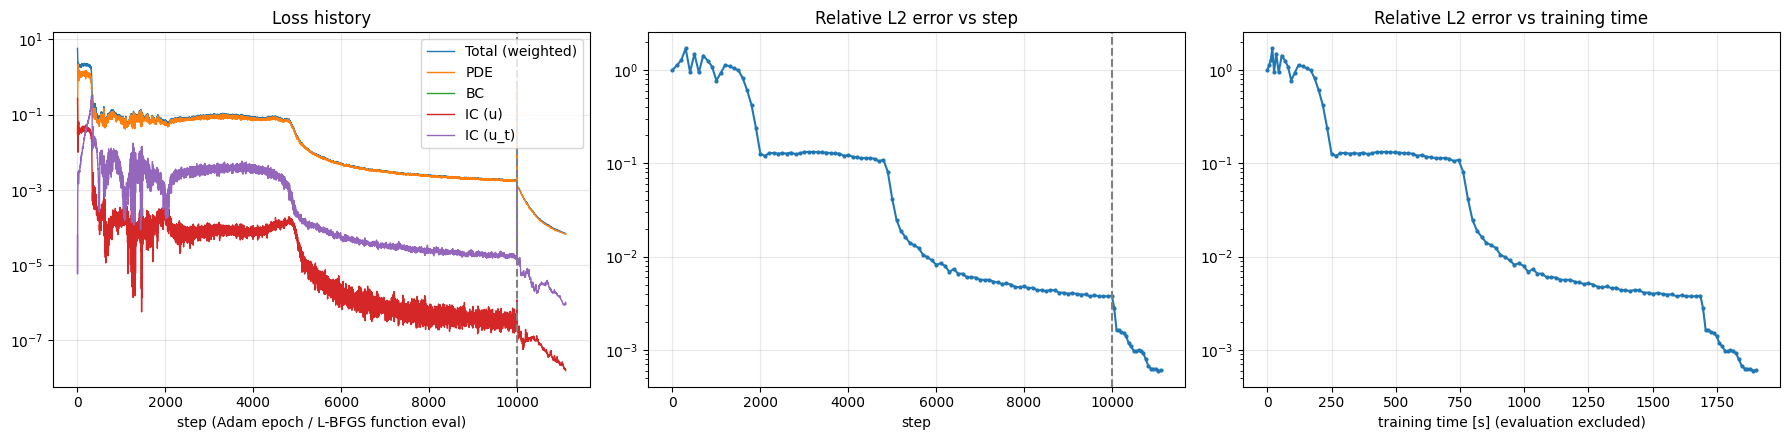

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

steps = np.arange(1, len(history["total"]) + 1)
for key, label in [("total", "Total (weighted)"), ("pde", "PDE"), ("bc", "BC"),
                   ("ic", "IC (u)"), ("ic_v", "IC (u_t)")]:
    ax[0].semilogy(steps, history[key], label=label, lw=1)
ax[0].set_title("Loss history")
ax[0].set_xlabel("step (Adam epoch / L-BFGS function eval)")
ax[0].legend()

ax[1].semilogy(history_err["step"], history_err["rel_l2"], "o-", ms=2)
ax[1].set_title("Relative L2 error vs step")
ax[1].set_xlabel("step")

ax[2].semilogy(history_err["time"], history_err["rel_l2"], "o-", ms=2)
ax[2].set_title("Relative L2 error vs training time")
ax[2].set_xlabel("training time [s] (evaluation excluded)")

if USE_LBFGS and stage_boundary is not None:
    for a in ax[:2]:
        a.axvline(stage_boundary, ls="--", color="gray")

for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

예측 / 정확해 / 절대오차 맵

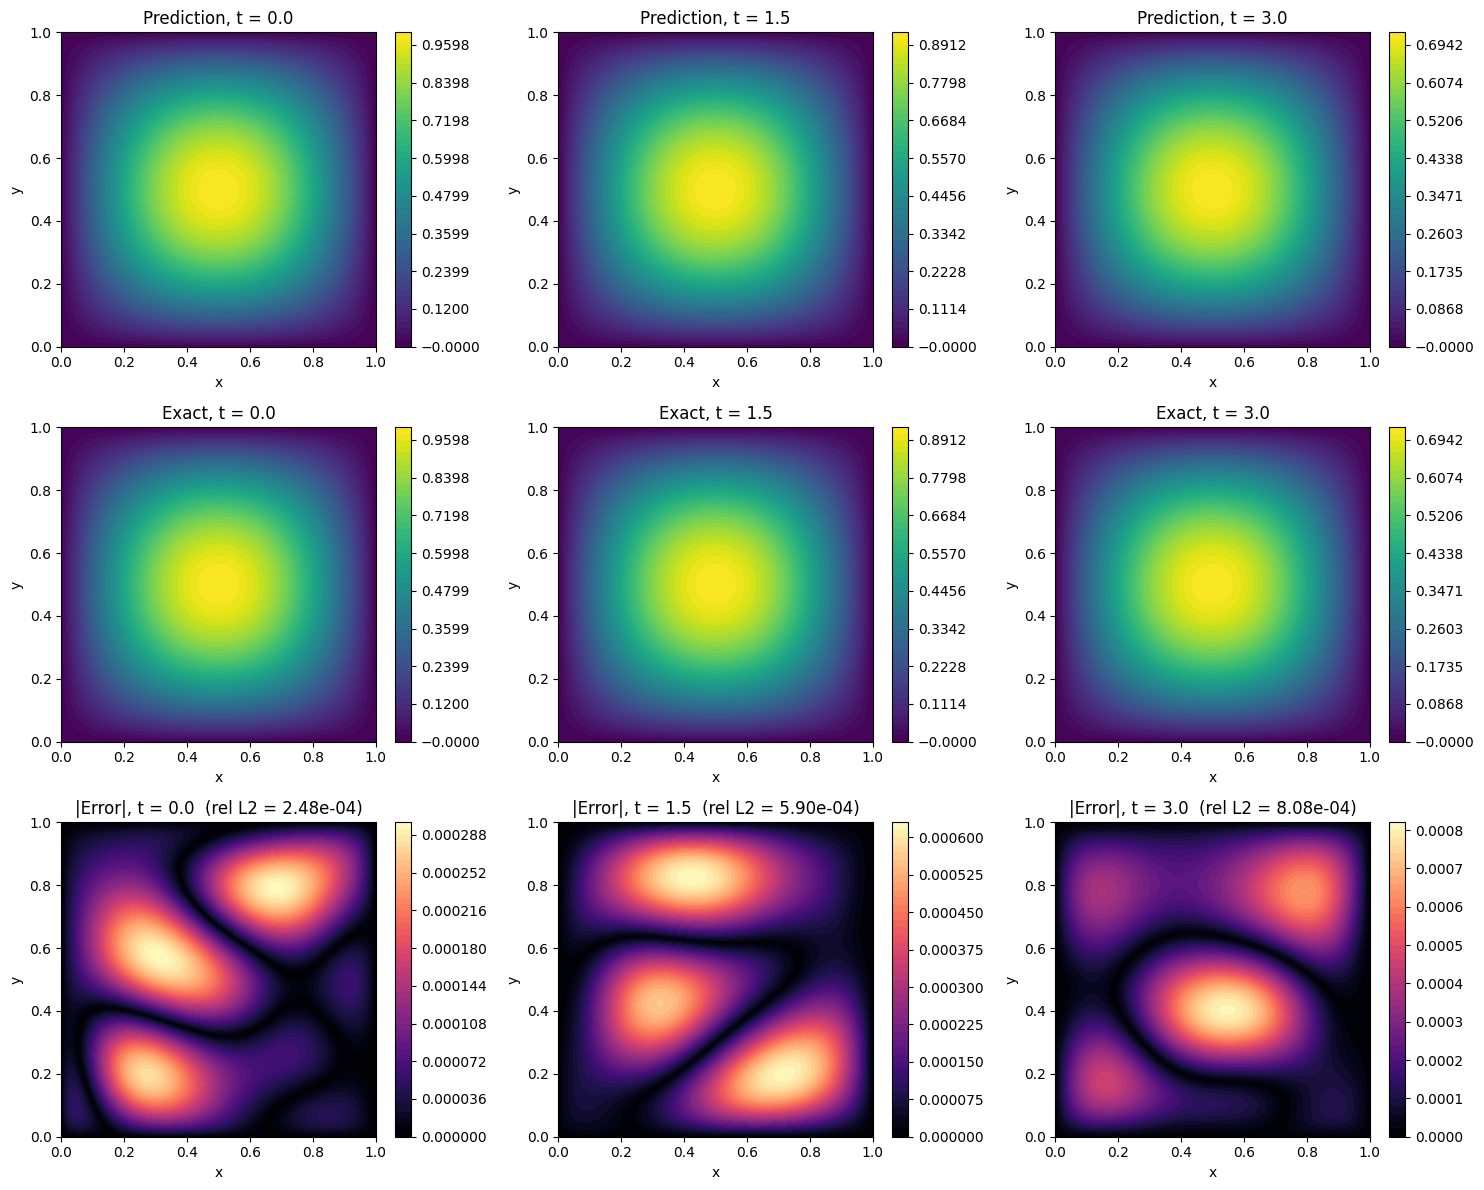

In [17]:
n = 100
xs = torch.linspace(0, 1, n, device=device)
Xg, Yg = torch.meshgrid(xs, xs, indexing="xy")
X_flat, Y_flat = Xg.reshape(-1, 1), Yg.reshape(-1, 1)
X_np, Y_np = Xg.cpu().numpy(), Yg.cpu().numpy()

times = [0.0, 0.5 * T, T]     # [TM] T 를 바꿔도 시작/중간/끝 시각을 그림
fig, axes = plt.subplots(3, len(times), figsize=(15, 12))

for j, t_val in enumerate(times):
    T_flat = torch.full_like(X_flat, t_val)

    with torch.no_grad():
        U_pred = model(X_flat, Y_flat, T_flat)
        U_true = exact(X_flat, Y_flat, T_flat, c)

    rel = (torch.linalg.norm(U_pred - U_true) / torch.linalg.norm(U_true)).item()

    P = U_pred.reshape(n, n).cpu().numpy()
    E = U_true.reshape(n, n).cpu().numpy()
    A = np.abs(P - E)

    # 예측과 정확해는 같은 색 범위를 사용해야 비교가 된다
    vmin, vmax = min(P.min(), E.min()), max(P.max(), E.max())
    levels = np.linspace(vmin, vmax, 51)

    cf0 = axes[0, j].contourf(X_np, Y_np, P, levels=levels, cmap="viridis")
    axes[0, j].set_title(f"Prediction, t = {t_val}")
    fig.colorbar(cf0, ax=axes[0, j])

    cf1 = axes[1, j].contourf(X_np, Y_np, E, levels=levels, cmap="viridis")
    axes[1, j].set_title(f"Exact, t = {t_val}")
    fig.colorbar(cf1, ax=axes[1, j])

    cf2 = axes[2, j].contourf(X_np, Y_np, A, levels=50, cmap="magma")
    axes[2, j].set_title(f"|Error|, t = {t_val}  (rel L2 = {rel:.2e})")
    fig.colorbar(cf2, ax=axes[2, j])

    for i in range(3):
        axes[i, j].set_xlabel("x")
        axes[i, j].set_ylabel("y")

plt.tight_layout()
plt.show()

[TM] 시간별 상대 $L_2$ 오차 (Time-Marching 효과 확인)
각 시각 $t$ 에서 공간 격자 위 상대 오차를 계산합니다. 인과성이 잘 지켜졌다면 $t$ 가 커져도 오차가 급격히 커지지 않습니다.
causal 모드면 마지막 인과성 가중치 $w_i$ 와 bin 별 PDE 손실도 함께 그립니다.

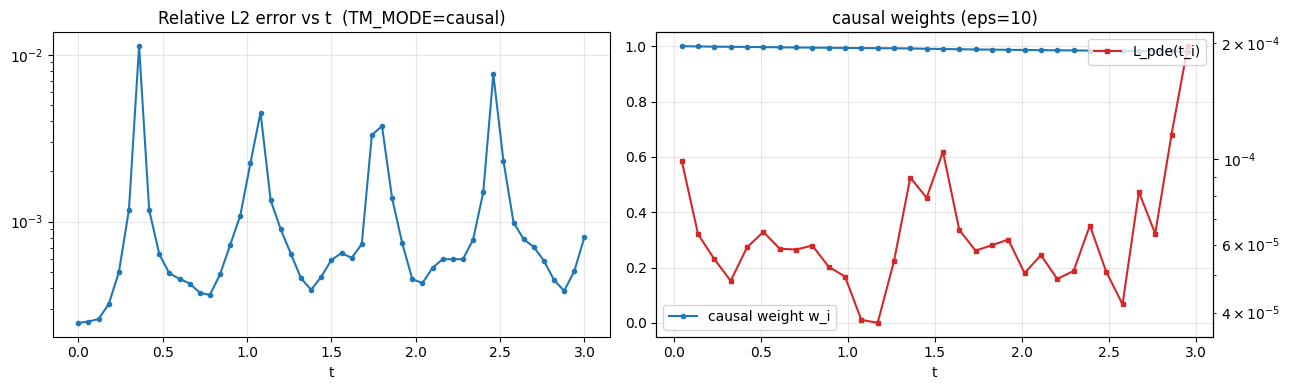

In [18]:
# [TM] 시간별 상대 L2 오차
t_line = np.linspace(0.0, T, 51)
err_t = []
with torch.no_grad():
    for t_val in t_line:
        T_flat = torch.full_like(X_flat, float(t_val))
        U_pred = model(X_flat, Y_flat, T_flat)
        U_true = exact(X_flat, Y_flat, T_flat, c)
        err_t.append((torch.linalg.norm(U_pred - U_true) / (torch.linalg.norm(U_true) + 1e-12)).item())
# 주의: cos(sqrt2*pi*c*t) = 0 근처에서는 정확해 크기가 0 에 가까워 상대 오차가 커 보일 수 있다

n_ax = 2 if (TM_MODE == "causal" and tm_state["w"] is not None) else 1
fig, ax = plt.subplots(1, n_ax, figsize=(6.5 * n_ax, 4), squeeze=False)
ax = ax[0]
ax[0].semilogy(t_line, err_t, "o-", ms=3)
if TM_MODE == "sequential":
    for e in TM_WINDOW_EDGES[1:-1]:
        ax[0].axvline(e, ls="--", color="gray")
ax[0].set_title(f"Relative L2 error vs t  (TM_MODE={TM_MODE})")
ax[0].set_xlabel("t")
ax[0].grid(alpha=0.3)

if n_ax == 2:
    centers = (np.arange(TM_CAUSAL_N_CHUNKS) + 0.5) / TM_CAUSAL_N_CHUNKS * T
    ax[1].plot(centers, tm_state["w"].cpu().numpy(), "o-", ms=3, label="causal weight w_i")
    ax1b = ax[1].twinx()
    ax1b.semilogy(centers, tm_state["L_t"].cpu().numpy(), "s-", ms=3, color="tab:red", label="L_pde(t_i)")
    ax[1].set_title(f"causal weights (eps={TM_CAUSAL_EPS_LIST[tm_state['eps_idx']]:g})")
    ax[1].set_xlabel("t")
    ax[1].set_ylim(-0.05, 1.05)
    ax[1].legend(loc="lower left")
    ax1b.legend(loc="upper right")
    ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


[AS] PDE 점이 어디에, 몇 개 쓰였는가
왼쪽: 시간 bin 별 PDE 점 개수가 학습이 진행되면서 어떻게 바뀌었는지 보여 줍니다. causal + `AS_SKIP` 이면 처음에는 $t=0$ 근처에만 점이 있고(뒤 시간대는 닫힘), 인과성 경계가 전진하면서 뒤 시간대가 차례로 열립니다.
오른쪽: step 마다 쓴 PDE 점 수입니다. 점선($N_f$)보다 아래에 있는 만큼 계산을 덜 한 것입니다.

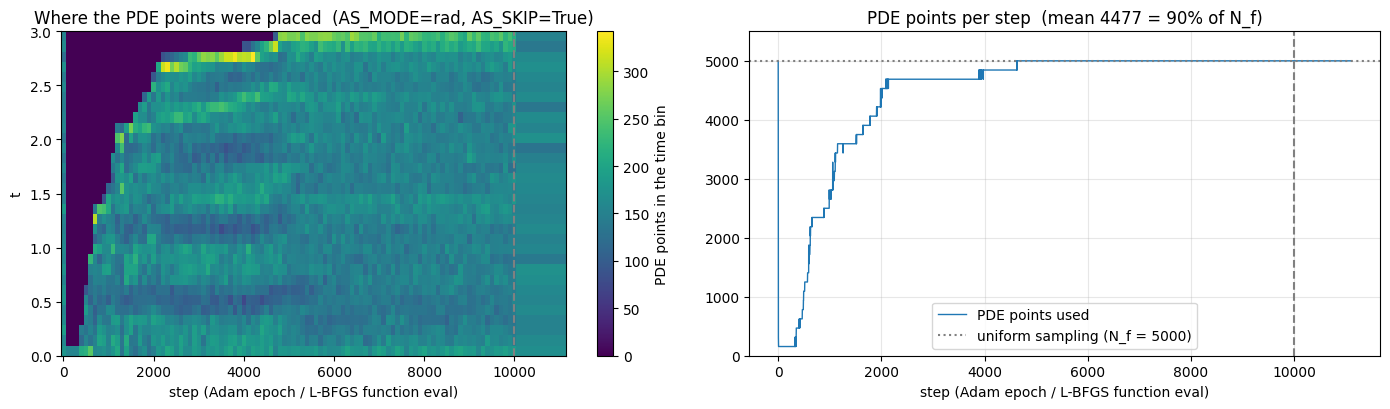

In [19]:
# [AS] (왼쪽) 시간 bin 별 PDE 점 개수의 변화   (오른쪽) step 별 PDE 점 수
cnt = np.array(history_as["counts"], dtype=float).T               # (N_t, 기록 횟수)
st = np.array(history_as["step"])
centers = (np.arange(TM_CAUSAL_N_CHUNKS) + 0.5) / TM_CAUSAL_N_CHUNKS * T

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
im = ax[0].pcolormesh(st, centers, cnt, shading="nearest", cmap="viridis")
fig.colorbar(im, ax=ax[0], label="PDE points in the time bin")
ax[0].set_title(f"Where the PDE points were placed  (AS_MODE={AS_MODE}, AS_SKIP={AS_SKIP_ON})")
ax[0].set_xlabel("step (Adam epoch / L-BFGS function eval)")
ax[0].set_ylabel("t")

n_pde = np.array(history["n_pde"])
ax[1].plot(np.arange(1, len(n_pde) + 1), n_pde, lw=1, label="PDE points used")
ax[1].axhline(N_f, ls=":", color="gray", label=f"uniform sampling (N_f = {N_f})")
ax[1].set_ylim(0, 1.1 * max(N_f, n_pde.max()))
ax[1].set_title(f"PDE points per step  (mean {n_pde.mean():.0f} = {100 * n_pde.mean() / N_f:.0f}% of N_f)")
ax[1].set_xlabel("step (Adam epoch / L-BFGS function eval)")
ax[1].legend()
ax[1].grid(alpha=0.3)

if USE_LBFGS and stage_boundary is not None:
    for a in ax:
        a.axvline(stage_boundary, ls="--", color="gray")
plt.tight_layout()
plt.show()

# **6번 [v3] 에너지·잔차 분석** (보고서 4~5장 수치 검증)

오차 $e=u_\theta-u$, 오차 에너지 $E_e(t)=\tfrac12\int_\Omega (e_t^2+c^2|\nabla e|^2)\,dx\,dy$.

| 확인 항목 | 식 | 비고 |
|---|---|---|
| 에너지 보존 | $E[u_\theta](t)$ vs $E[u]=\pi^2c^2/4$ (상수) | 정확해의 에너지는 시간에 무관 |
| 에너지 오차 추정 (4.2절) | $\sqrt{E_e(t)}\le\sqrt{E_e(0)}+\tfrac{1}{\sqrt2}\int_0^t\lVert r_\theta(\cdot,s)\rVert_{L^2(\Omega)}ds$ | $\tfrac{d}{dt}E_e\le\sqrt{2E_e}\,\lVert r\rVert$ 에서 유도. **$e|_{\partial\Omega}=0$ 가정** → `HARD_BC=True` 에서만 엄밀 |
| $L^2$ 오차 상계 (푸앵카레) | $\lVert e(\cdot,t)\rVert_{L^2}\le \sqrt{E_e(t)}/(\pi c)$ | 마찬가지로 $e|_{\partial\Omega}=0$ 필요 |
| 일반화 간극 (5.1절) | 학습 점의 $L_{pde}$ vs 새 점 $N_{gap}$ 개의 $L_{pde}^{cont}$ | $\sqrt{E_e(T)}\le\sqrt{E_e(0)}+\tfrac{T}{\sqrt2}\sqrt{L^{cont}_{pde}}$ |

적분은 $[0,1]^2$ 중점 규칙(격자 평균 = 적분, $|\Omega|=1$), 시간 적분은 사다리꼴 규칙.

정확해 에너지 E = pi^2 c^2 / 4 = 2.46740
PINN 에너지 상대 오차: 평균 1.381e-04, 최대 3.046e-04
sqrt(E_e): t=0 1.104e-03 -> t=T 2.498e-03,  추정식 우변(t=T) 1.988e-02,  모든 t 에서 성립: True


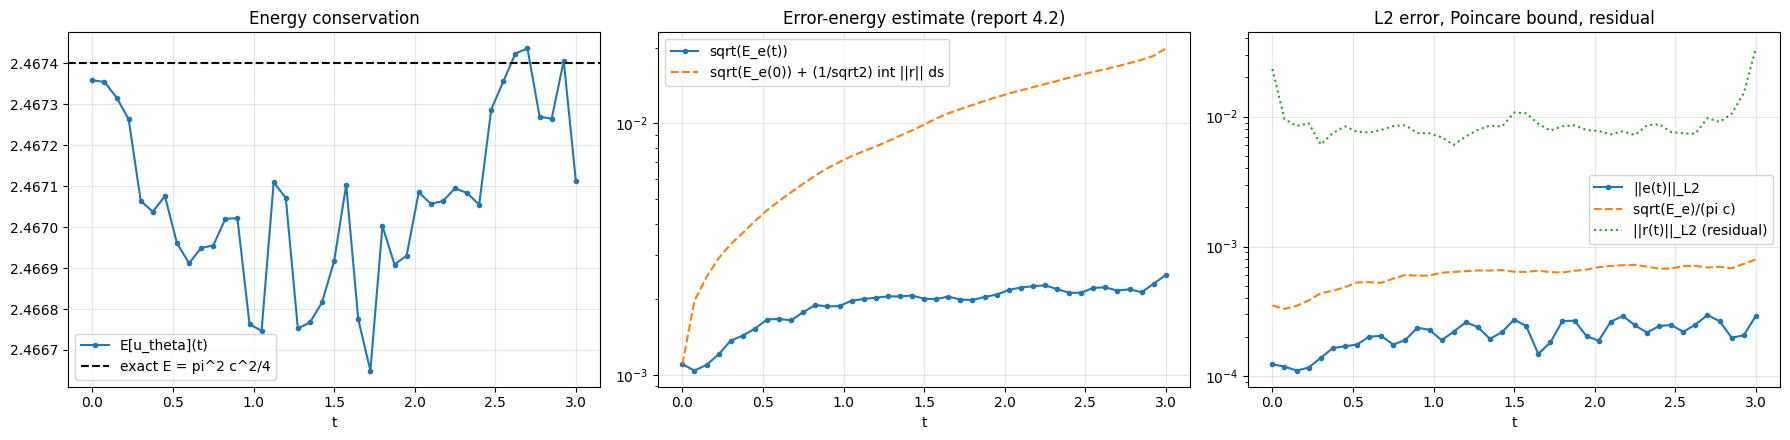

In [20]:
# ============================================
# [v3] 6. 에너지 / 잔차 / 오차 에너지 추정식 검증
# ============================================
OMEGA = math.sqrt(2) * math.pi * c          # 정확해의 각진동수
E_EXACT = math.pi ** 2 * c ** 2 / 4         # 정확해의 에너지 (상수)


def exact_derivs(x, y, t):
    """정확해 u 와 u_x, u_y, u_t (u0 = sin(pi x) sin(pi y), v0 = 0 전용)."""
    s, ct, st = torch.sin(torch.pi * x) * torch.sin(torch.pi * y), torch.cos(OMEGA * t), torch.sin(OMEGA * t)
    u = s * ct
    u_x = torch.pi * torch.cos(torch.pi * x) * torch.sin(torch.pi * y) * ct
    u_y = torch.pi * torch.sin(torch.pi * x) * torch.cos(torch.pi * y) * ct
    u_t = -OMEGA * s * st
    return u, u_x, u_y, u_t


def pinn_derivs(model, x, y, t, need_residual=True):
    """PINN 의 u, u_x, u_y, u_t 와 PDE 잔차 r (모두 detach)."""
    x = x.clone().detach().requires_grad_(True)
    y = y.clone().detach().requires_grad_(True)
    t = t.clone().detach().requires_grad_(True)
    u = model(x, y, t)
    u_x, u_y, u_t = torch.autograd.grad(u, (x, y, t), torch.ones_like(u), create_graph=need_residual)
    r = None
    if need_residual:
        u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), retain_graph=True)[0]
        u_yy = torch.autograd.grad(u_y, y, torch.ones_like(u_y), retain_graph=True)[0]
        u_tt = torch.autograd.grad(u_t, t, torch.ones_like(u_t))[0]
        r = (u_tt - c ** 2 * (u_xx + u_yy)).detach()
    return u.detach(), u_x.detach(), u_y.detach(), u_t.detach(), r


_s = (torch.arange(N_GRID_EVAL, device=device, dtype=torch.float32) + 0.5) / N_GRID_EVAL   # 중점
_Xm, _Ym = torch.meshgrid(_s, _s, indexing="xy")
xm, ym = _Xm.reshape(-1, 1), _Ym.reshape(-1, 1)

t_eval = np.linspace(0.0, T, N_T_EVAL)
E_pinn, E_err, res_norm, err_norm = [], [], [], []
for t_val in t_eval:
    tm_ = torch.full_like(xm, float(t_val))
    u, u_x, u_y, u_t, r = pinn_derivs(model, xm, ym, tm_)
    ue, ue_x, ue_y, ue_t = exact_derivs(xm, ym, tm_)
    E_pinn.append(0.5 * torch.mean(u_t ** 2 + c ** 2 * (u_x ** 2 + u_y ** 2)).item())
    E_err.append(0.5 * torch.mean((u_t - ue_t) ** 2 + c ** 2 * ((u_x - ue_x) ** 2 + (u_y - ue_y) ** 2)).item())
    res_norm.append(torch.sqrt(torch.mean(r ** 2)).item())
    err_norm.append(torch.sqrt(torch.mean((u - ue) ** 2)).item())

E_pinn, E_err, res_norm, err_norm = map(np.array, (E_pinn, E_err, res_norm, err_norm))
int_res = np.concatenate([[0.0], np.cumsum(0.5 * (res_norm[1:] + res_norm[:-1]) * np.diff(t_eval))])
bound_energy = np.sqrt(E_err[0]) + int_res / math.sqrt(2)      # 4.2절 우변
bound_l2 = np.sqrt(E_err) / (math.pi * c)                      # 푸앵카레 상계

rel_energy_drift = np.abs(E_pinn - E_EXACT) / E_EXACT
holds = np.all(np.sqrt(E_err) <= bound_energy * (1 + 1e-6))
print(f"정확해 에너지 E = pi^2 c^2 / 4 = {E_EXACT:.5f}")
print(f"PINN 에너지 상대 오차: 평균 {rel_energy_drift.mean():.3e}, 최대 {rel_energy_drift.max():.3e}")
print(f"sqrt(E_e): t=0 {np.sqrt(E_err[0]):.3e} -> t=T {np.sqrt(E_err[-1]):.3e},  "
      f"추정식 우변(t=T) {bound_energy[-1]:.3e},  모든 t 에서 성립: {holds}"
      + ("" if HARD_BC else "   (HARD_BC=False: 경계 오차가 있어 엄밀한 가정은 아님)"))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(t_eval, E_pinn, "o-", ms=3, label="E[u_theta](t)")
ax[0].axhline(E_EXACT, color="k", ls="--", label="exact E = pi^2 c^2/4")
ax[0].set_title("Energy conservation")
ax[0].legend()

ax[1].semilogy(t_eval, np.sqrt(E_err), "o-", ms=3, label="sqrt(E_e(t))")
ax[1].semilogy(t_eval, bound_energy, "--", label="sqrt(E_e(0)) + (1/sqrt2) int ||r|| ds")
ax[1].set_title("Error-energy estimate (report 4.2)")
ax[1].legend()

ax[2].semilogy(t_eval, err_norm, "o-", ms=3, label="||e(t)||_L2")
ax[2].semilogy(t_eval, bound_l2, "--", label="sqrt(E_e)/(pi c)")
ax[2].semilogy(t_eval, res_norm, ":", label="||r(t)||_L2 (residual)")
ax[2].set_title("L2 error, Poincare bound, residual")
ax[2].legend()
for a in ax:
    a.set_xlabel("t")
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [21]:
# [v3] 5.1절: 학습 점에서의 PDE 손실 vs 새 점에서의 연속 손실 추정 (일반화 간극)
def mean_residual_sq(model, x, y, t, batch=10000):
    total = 0.0
    for k in range(0, x.shape[0], batch):
        r = pinn_derivs(model, x[k:k + batch], y[k:k + batch], t[k:k + batch])[-1]
        total += (r ** 2).sum().item()
    return total / x.shape[0]


_g2 = torch.Generator(device=device)
_g2.manual_seed(4321)
xg = torch.rand(N_GAP, 1, device=device, generator=_g2)
yg = torch.rand(N_GAP, 1, device=device, generator=_g2)
tg = torch.rand(N_GAP, 1, device=device, generator=_g2) * T

L_train = mean_residual_sq(model, pts[0], pts[1], pts[2])     # 마지막으로 학습에 쓴 점 (가중치 없는 평균)
L_cont = mean_residual_sq(model, xg, yg, tg)                  # 연속 평균의 불편추정
print(f"L_pde (학습 점 {pts[0].shape[0]}개)  : {L_train:.3e}")
print(f"L_pde^cont (새 점 {N_GAP}개)  : {L_cont:.3e}   (간극 비 {L_cont / max(L_train, 1e-30):.2f}배)")
print(f"sqrt(E_e(T)) = {np.sqrt(E_err[-1]):.3e}  <=  sqrt(E_e(0)) + T/sqrt2 * sqrt(L_cont) = "
      f"{np.sqrt(E_err[0]) + T / math.sqrt(2) * math.sqrt(L_cont):.3e}")


L_pde (학습 점 5000개)  : 6.678e-05
L_pde^cont (새 점 50000개)  : 7.980e-05   (간극 비 1.19배)
sqrt(E_e(T)) = 2.498e-03  <=  sqrt(E_e(0)) + T/sqrt2 * sqrt(L_cont) = 2.005e-02


# **7번 [v3] FDM 기준선과 비교** (보고서 7장, 8.2절)

명시적 중앙차분(leapfrog): $u^{n+1}_{ij}=2u^n_{ij}-u^{n-1}_{ij}+\lambda^2(u^n_{i+1,j}+u^n_{i-1,j}+u^n_{i,j+1}+u^n_{i,j-1}-4u^n_{ij})$, $\lambda=c\Delta t/h$
첫 단계는 테일러 전개 $u^1=u^0+\Delta t\,v_0+\tfrac{\lambda^2}{2}\Delta_h u^0$ (2차 정확도).
안정 조건(CFL): $(c\Delta t/\Delta x)^2+(c\Delta t/\Delta y)^2\le1$, 즉 $\Delta x=\Delta y=h$ 이면 $c\Delta t/h\le 1/\sqrt2$.
절단 오차 $O(\Delta t^2+h^2)$ → CFL 고정 상태로 $h$ 를 반으로 줄이면 오차는 약 1/4 (수렴 차수 2).

In [22]:
# ============================================
# [v3] 7. FDM (explicit leapfrog) 기준선
# ============================================
def fdm_wave(nx, T_end, c=1.0, cfl=FDM_CFL, save_times=()):
    """단위 정사각형, u=0 경계, u0 = sin(pi x) sin(pi y), v0 = 0.  반환: X, Y, {t: u}, info"""
    h = 1.0 / (nx - 1)
    nt = math.ceil(T_end / (cfl * h / c))
    nt += nt % 2                                   # 짝수 -> T/2 가 정확히 격자 위
    dt = T_end / nt
    lam2 = (c * dt / h) ** 2
    assert 2 * lam2 <= 1.0 + 1e-12, f"CFL 위반: c dt / h = {math.sqrt(lam2):.3f} > 1/sqrt(2)"

    xs = np.linspace(0.0, 1.0, nx)
    X, Y = np.meshgrid(xs, xs, indexing="xy")
    save_steps = {int(round(ts / dt)): ts for ts in save_times}
    snaps = {}

    def lap(u):                                   # 5점 라플라시안 * h^2 (내부점)
        return u[2:, 1:-1] + u[:-2, 1:-1] + u[1:-1, 2:] + u[1:-1, :-2] - 4.0 * u[1:-1, 1:-1]

    t0 = time.time()
    u_prev = np.sin(np.pi * X) * np.sin(np.pi * Y)
    u_prev[0, :] = u_prev[-1, :] = u_prev[:, 0] = u_prev[:, -1] = 0.0
    v0 = np.zeros_like(u_prev)
    u_curr = np.zeros_like(u_prev)
    u_curr[1:-1, 1:-1] = u_prev[1:-1, 1:-1] + dt * v0[1:-1, 1:-1] + 0.5 * lam2 * lap(u_prev)
    if 0 in save_steps:
        snaps[save_steps[0]] = u_prev.copy()
    if 1 in save_steps:
        snaps[save_steps[1]] = u_curr.copy()

    u_next = np.zeros_like(u_prev)
    for n in range(1, nt):
        u_next[1:-1, 1:-1] = 2.0 * u_curr[1:-1, 1:-1] - u_prev[1:-1, 1:-1] + lam2 * lap(u_curr)
        u_prev, u_curr, u_next = u_curr, u_next, u_prev
        if n + 1 in save_steps:
            snaps[save_steps[n + 1]] = u_curr.copy()
    info = dict(nx=nx, h=h, nt=nt, dt=dt, cfl=math.sqrt(lam2), time=time.time() - t0)
    return X, Y, snaps, info


def exact_np(X, Y, t):
    return np.sin(np.pi * X) * np.sin(np.pi * Y) * np.cos(math.sqrt(2) * np.pi * c * t)


# (1) 수렴 차수 확인
print("FDM 수렴 차수 (t = T, CFL 고정)")
prev = None
for nx in FDM_CONV_NX:
    X, Y, snaps, info = fdm_wave(nx, T, c, save_times=[T])
    E = exact_np(X, Y, T)
    err = np.linalg.norm(snaps[T] - E) / np.linalg.norm(E)
    order = "" if prev is None else f"  order {math.log2(prev / err):.2f}"
    print(f"  nx={nx:4d}  h={info['h']:.4f}  nt={info['nt']:5d}  relL2={err:.3e}  time={info['time']:.3f}s{order}")
    prev = err


FDM 수렴 차수 (t = T, CFL 고정)
  nx=  21  h=0.0500  nt=  120  relL2=6.525e-03  time=0.002s
  nx=  41  h=0.0250  nt=  240  relL2=1.634e-03  time=0.006s  order 2.00
  nx=  81  h=0.0125  nt=  480  relL2=4.088e-04  time=0.019s  order 2.00
  nx= 161  h=0.0063  nt=  960  relL2=1.022e-04  time=0.119s  order 2.00


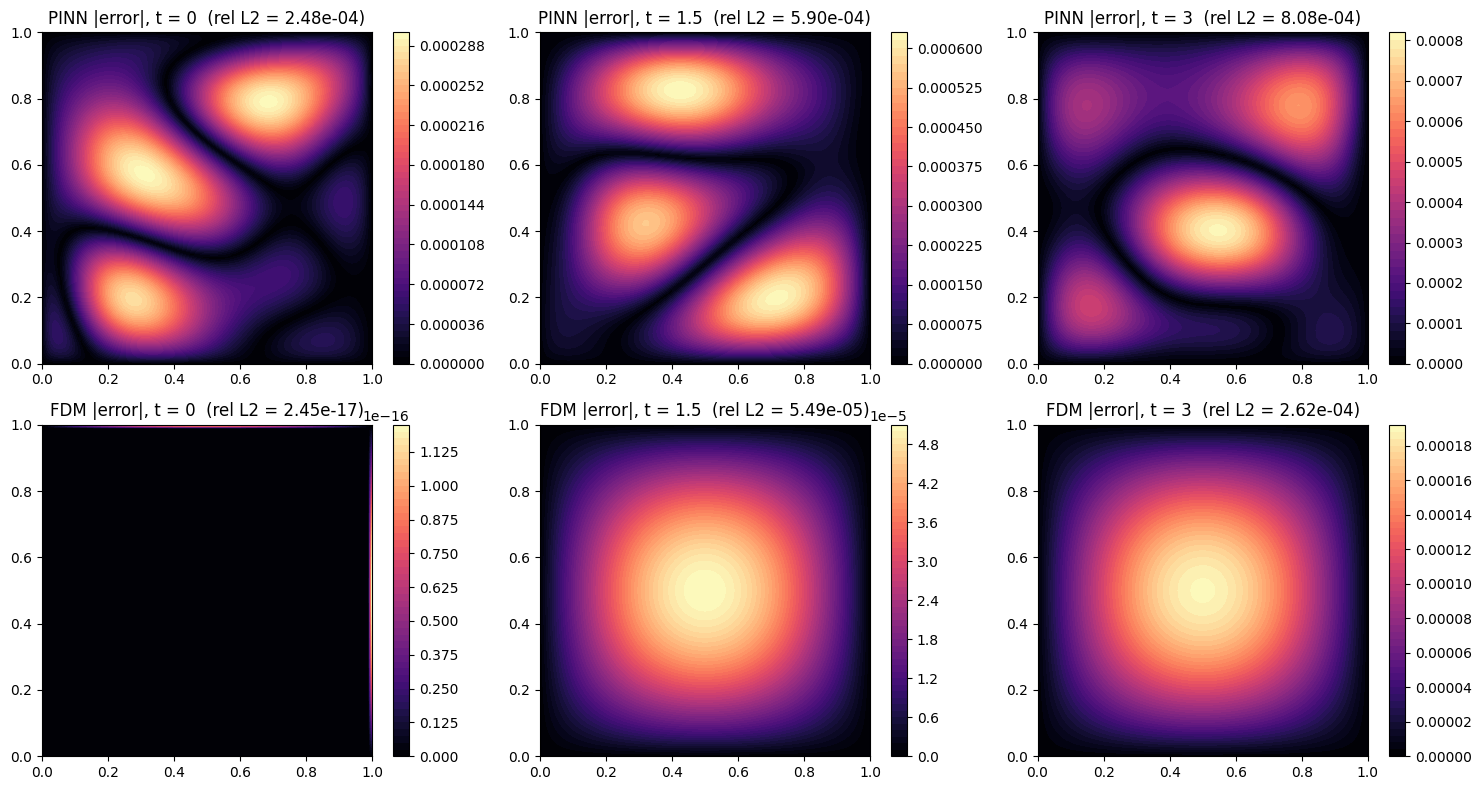

     t |  PINN relL2 |  FDM relL2
 0.000 |   2.476e-04 |  2.449e-17
 1.500 |   5.898e-04 |  5.491e-05
 3.000 |   8.081e-04 |  2.616e-04
계산 시간: PINN 학습 1900.9s  vs  FDM 0.138s (nx=101, nt=600, c dt/h=0.500)


In [23]:
# (2) PINN vs FDM: 같은 격자점, 같은 시각에서 정확해 대비 오차
cmp_times = [0.0, 0.5 * T, T]
X, Y, snaps, info = fdm_wave(FDM_NX, T, c, save_times=cmp_times)
Xt = torch.tensor(X.reshape(-1, 1), dtype=torch.float32, device=device)
Yt = torch.tensor(Y.reshape(-1, 1), dtype=torch.float32, device=device)

fig, axes = plt.subplots(2, len(cmp_times), figsize=(15, 8))
rows = []
for j, t_val in enumerate(cmp_times):
    E = exact_np(X, Y, t_val)
    with torch.no_grad():
        P = model(Xt, Yt, torch.full_like(Xt, t_val)).cpu().numpy().reshape(X.shape)
    F = snaps[t_val]
    nE = np.linalg.norm(E) + 1e-12
    e_p, e_f = np.linalg.norm(P - E) / nE, np.linalg.norm(F - E) / nE
    rows.append((t_val, e_p, e_f))
    for i, (A, name, e) in enumerate([(np.abs(P - E), "PINN", e_p), (np.abs(F - E), "FDM", e_f)]):
        cf = axes[i, j].contourf(X, Y, A, levels=50, cmap="magma")
        axes[i, j].set_title(f"{name} |error|, t = {t_val:.3g}  (rel L2 = {e:.2e})")
        fig.colorbar(cf, ax=axes[i, j])
plt.tight_layout()
plt.show()

print(f"{'t':>6} | {'PINN relL2':>11} | {'FDM relL2':>10}")
for t_val, e_p, e_f in rows:
    print(f"{t_val:6.3f} | {e_p:11.3e} | {e_f:10.3e}")
print(f"계산 시간: PINN 학습 {train_time:.1f}s  vs  FDM {info['time']:.3f}s "
      f"(nx={info['nx']}, nt={info['nt']}, c dt/h={info['cfl']:.3f})")


모델 / 설정 / 학습 이력 저장

In [24]:
# [v3] 가중치뿐 아니라 설정·학습 이력도 함께 저장 (실험 비교/재현용)
config = {k: v for k, v in globals().items()
          if k.isupper() and not k.startswith("_") and isinstance(v, (bool, int, float, str, list, dict))}
config.update(N_f=N_f, N_bc=N_bc, N_ic=N_ic, c=c, T=T)
save_path = f"pinn_{RUN_NAME}.pt"          # [AS] 실행마다 다른 이름으로 저장 -> 8번에서 비교
torch.save({"state_dict": model.state_dict(), "train_time": train_time,
            "config": config, "history": history, "history_err": history_err,
            "history_as": history_as, "stage_boundary": stage_boundary}, save_path)
print("saved:", save_path)


saved: pinn_adaptive.pt


# **8번 [AS] 여러 실행 비교** (균등 샘플링 vs 중요도 기반)

이 노트북을 **0번 셀의 설정만 바꿔 여러 번 "모두 실행"** 하면, 실행마다 `pinn_<RUN_NAME>.pt` 가 남고 아래 셀이 모두 읽어 비교합니다.

| 실행 | 0번 셀 설정 |
|---|---|
| 기준 (v3 방식) | `AS_MODE = "none"`, `AS_SKIP = False`, `RUN_NAME = "uniform"` |
| 건너뛰기만 | `AS_MODE = "none"`, `AS_SKIP = True`, `RUN_NAME = "skip"` |
| 건너뛰기 + 잔차 기반 | `AS_MODE = "rad"`, `AS_SKIP = True`, `RUN_NAME = "adaptive"` |

- 가로축 **누적 PDE 점 계산 수**는 잔차(2계 미분)를 계산한 점의 총 개수로, 실행 환경과 무관한 계산량입니다. 같은 오차에 더 왼쪽에서 도달하면 더 적은 계산으로 푼 것입니다.
- **학습 시간**은 실행 환경에 따라 다릅니다. GPU 에서는 `N_f` 가 수천 개 수준이면 epoch 당 시간이 점 수에 거의 비례하지 않아 차이가 작게 보입니다. `N_f` 를 크게(수만 개 이상) 잡으면 차이가 드러납니다.
- Colab 런타임을 다시 시작하면 저장된 파일이 지워집니다.

### 이 노트북을 만들면서 측정한 값 (참고)

조건: CPU, `T = 3`, `TM_CAUSAL_EPS_LIST = [1, 10, 100]`, `N_f = 2000`, Adam 10000 → L-BFGS, seed 4개. 범위는 seed 간 최소 ~ 최대입니다.

| 실행 | PDE 점 계산 수 | 인과성 경계가 $t=T$ 에 도달한 epoch | Adam 끝 relL2 | 최종 relL2 |
|---|---|---|---|---|
| 기준: 균등, 건너뛰기 없음 | 100% | (모든 시간대를 항상 계산) | 1.2e-2 ~ 6.7e-2 | 5.6e-4 ~ 9.8e-4 |
| 건너뛰기만 | 85 ~ 88% | 5500 ~ 9700 | 8.4e-3 ~ 1.1e-1 | 7.0e-4 ~ 1.2e-3 |
| 건너뛰기 + 잔차 기반 | 96 ~ 97% | 3600 ~ 4500 | 3.3e-3 ~ 4.8e-3 | 4.8e-4 ~ 8.1e-4 |

- **최종 오차는 세 방식이 seed 편차 안에서 같습니다.** 최종 정확도는 L-BFGS 단계가 결정합니다.
- **건너뛰기**는 닫힌 시간대의 계산만 빼므로, 정확도를 잃지 않고 PDE 점 계산을 12 ~ 15% 줄였습니다.
- **잔차 기반**을 더하면 Adam 단계가 빨라졌습니다. 인과성 경계 근처에 점이 몰려 경계가 더 일찍 끝까지 갔고, Adam 끝 오차가 네 seed 모두에서 기준보다 낮았습니다. 후보 점을 계산하는 비용이 들어 계산량은 기준과 비슷합니다.
- **점 수를 줄이는 것이 더 큰 절감이었습니다.** Adam 단계에서만 PDE 점을 균등하게 절반(1090개)으로 줄인 대조 실행도 최종 relL2 가 7.9e-4 ~ 8.3e-4 로 같았고, 계산은 59%였습니다(seed 2개). 이 문제에서는 Adam 단계의 `N_f = 2000` 이 넉넉하다는 뜻입니다. 점 밀도를 인과성 가중치에 비례시키는 방식도 시험했지만 이 대조 실행과 결과가 같아서 넣지 않았습니다.
- `T = 1`, v3 의 eps 목록에서는 닫히는 시간대가 없어 건너뛰기가 하는 일이 없고, 방식 간 차이도 없었습니다(최종 relL2 1.0e-3 ~ 1.5e-3).
- 같은 `T = 3` 에서 eps 목록만 v3 것으로 바꾸면 최종 relL2 가 1.3e-3 ~ 3.3e-3, 인과성 가중치를 끄면(`TM_MODE = "none"`) 1.4e-3 ~ 5.5e-3 이었습니다(seed 2개). 이 조건에서는 강한 인과성이 정확도에 도움이 됩니다.

RUN_NAME         AS_MODE AS_SKIP     N_f  final relL2  time [s]  PDE point evals  vs uniform
adaptive         rad     True       5000    6.065e-04    1900.9        5.417e+07         98%


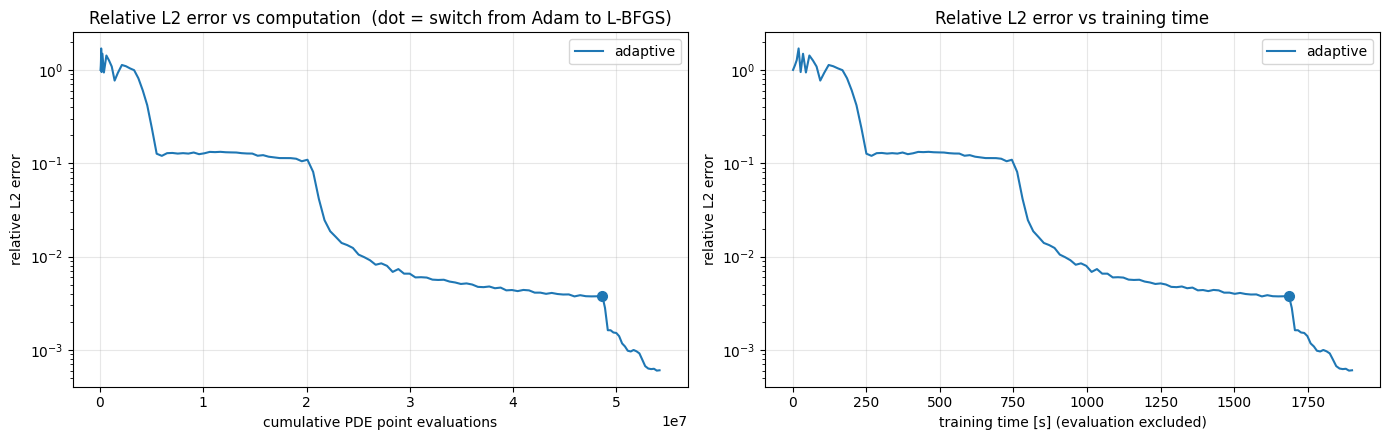

In [25]:
# ============================================
# [AS] 8. 저장된 실행(pinn_*.pt) 비교
# ============================================
import glob

runs = []
for path in sorted(glob.glob("pinn_*.pt")):
    d = torch.load(path, map_location="cpu")
    if "n_pts" in d.get("history_err", {}):          # 이 노트북이 저장한 파일만
        runs.append((path[len("pinn_"):-len(".pt")], d))

print(f"{'RUN_NAME':<16} {'AS_MODE':<8}{'AS_SKIP':<8}{'N_f':>7}{'final relL2':>13}{'time [s]':>10}{'PDE point evals':>17}{'vs uniform':>12}")
for name, d in runs:
    cfg, he = d["config"], d["history_err"]
    n_uniform = cfg["N_f"] * len(d["history"]["total"])      # 균등 샘플링이었다면 계산했을 점 수
    print(f"{name:<16} {cfg['AS_MODE']:<8}{str(cfg['AS_SKIP_ON']):<8}{cfg['N_f']:>7}{he['rel_l2'][-1]:>13.3e}"
          f"{d['train_time']:>10.1f}{he['n_pts'][-1]:>17.3e}{100 * he['n_pts'][-1] / n_uniform:>11.0f}%")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, d in runs:
    he = d["history_err"]
    for a, key in zip(ax, ("n_pts", "time")):
        line, = a.semilogy(he[key], he["rel_l2"], "-", lw=1.5, label=name)
        if d.get("stage_boundary") in he["step"]:                 # 큰 점 = Adam -> L-BFGS 전환
            k = he["step"].index(d["stage_boundary"])
            a.plot(he[key][k], he["rel_l2"][k], "o", ms=7, color=line.get_color())
ax[0].set_title("Relative L2 error vs computation  (dot = switch from Adam to L-BFGS)")
ax[0].set_xlabel("cumulative PDE point evaluations")
ax[1].set_title("Relative L2 error vs training time")
ax[1].set_xlabel("training time [s] (evaluation excluded)")
for a in ax:
    a.set_ylabel("relative L2 error")
    a.grid(alpha=0.3)
    a.legend()
plt.tight_layout()
plt.show()